In [4]:
# Quick test - basic imports
import sys
print(f"Python version: {sys.version}")
print("Basic import successful!")

Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Basic import successful!


## 1. Import Required Libraries

In [71]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Scikit-learn utilities
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, RFE, mutual_info_classif
from sklearn.decomposition import PCA

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Advanced ML libraries (optional - install libomp via brew if needed)
try:
    import xgboost as xgb
    print("✓ XGBoost imported successfully")
except Exception as e:
    print(f"⚠ XGBoost not available. Run: brew install libomp")
    xgb = None

try:
    import lightgbm as lgb
    print("✓ LightGBM imported successfully")
except Exception as e:
    print(f"⚠ LightGBM not available: {str(e)[:50]}...")
    lgb = None

try:
    from catboost import CatBoostClassifier
    print("✓ CatBoost imported successfully")
except Exception as e:
    print(f"⚠ CatBoost not available: {str(e)[:50]}...")
    CatBoostClassifier = None

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    confusion_matrix, classification_report, matthews_corrcoef
)

# Handling imbalanced data
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek, SMOTEENN

# Model interpretation
try:
    import shap
    print("✓ SHAP imported successfully")
except Exception as e:
    print(f"⚠ SHAP not available: {str(e)[:50]}...")
    shap = None

try:
    from lime import lime_tabular
    print("✓ LIME imported successfully")
except Exception as e:
    print(f"⚠ LIME not available: {str(e)[:50]}...")
    lime_tabular = None

# Model persistence
import joblib
import pickle

# Statistical analysis
from scipy import stats
from scipy.stats import zscore

# Date handling
from datetime import datetime

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("\n" + "="*60)
print("✓ Core libraries imported successfully!")
print("="*60)
print(f"Python version: {sys.version}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print("="*60)

✓ XGBoost imported successfully
✓ LightGBM imported successfully
⚠ CatBoost not available: No module named 'catboost'...
✓ SHAP imported successfully
⚠ LIME not available: No module named 'lime'...

✓ Core libraries imported successfully!
Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Pandas version: 2.2.3
NumPy version: 1.26.4
Scikit-learn version: 1.5.1


## 2. Define File Paths and Configuration

In [6]:
# Base directory
BASE_DIR = Path('/Users/roya/Desktop/Thesis')
DATA_DIR = BASE_DIR / 'Data set'
OUTPUT_DIR = BASE_DIR / 'Thesis_Project' / 'ML' / 'ML_Fraud_Detection_1_outputs'

# Data file paths
PART_B_FILE = DATA_DIR / 'Part B' / '2023' / 'MUP_PHY_R25_P05_V20_D23_Prov_Svc.csv'
PART_D_FILE = DATA_DIR / 'Medicare Part D Prescribers - by Provider and Drug' / '2023' / 'MUP_DPR_RY25_P04_V10_DY23_NPIBN.csv'
OIG_FILE = DATA_DIR / 'OIG.csv'

# Create output directories
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)
(OUTPUT_DIR / 'reports').mkdir(exist_ok=True)

print("✓ File paths configured")
print(f"Base Directory: {BASE_DIR}")
print(f"Data Directory: {DATA_DIR}")
print(f"Output Directory: {OUTPUT_DIR}")


✓ File paths configured
Base Directory: /Users/roya/Desktop/Thesis
Data Directory: /Users/roya/Desktop/Thesis/Data set
Output Directory: /Users/roya/Desktop/Thesis/Thesis_Project/ML/ML_Fraud_Detection_1_outputs


## 3. Data Loading & Initial Exploration

### 3.1 Load Medicare Part B Data

In [7]:
# Load Part B data (Provider Services)
print("Loading Medicare Part B 2023 data...")
part_b_df = pd.read_csv(PART_B_FILE, low_memory=False)

print(f"Part B Data Shape: {part_b_df.shape}")
print(f"\nMemory Usage: {part_b_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
part_b_df.head()

Loading Medicare Part B 2023 data...
Part B Data Shape: (9660647, 28)

Memory Usage: 11188.00 MB


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99221,Initial hospital care with straightforward or ...,N,F,12,12.0000,12,250.2267,89.0625,60.3125,54.6692
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99222,Initial hospital care with straightforward or ...,N,F,22,22.0000,22,318.5818,130.3127,99.3800,98.4295
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99231,Subsequent hospital care with straightforward ...,N,F,76,127.0000,127,95.7323,54.8202,43.5573,38.7487
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99232,Subsequent hospital care with moderate levelof...,N,F,180,341.0000,341,194.4415,86.8408,69.0864,61.8123
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99233,Subsequent hospital care with moderate levelof...,N,F,53,79.0000,79,251.4541,127.9152,100.9432,92.4091


### 3.2

In [8]:
# Filter to include only U.S. states and territories

us_states = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 
             'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD', 
             'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 
             'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 
             'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY', 
             'DC', 'PR', 'VI', 'GU', 'AS', 'MP']

before_filter_b = len(part_b_df)
part_b_df = part_b_df[part_b_df['Rndrng_Prvdr_State_Abrvtn'].isin(us_states)]
after_filter_b = len(part_b_df)
removed_b = before_filter_b - after_filter_b

print(f"Part B: Removed {removed_b:,} non-U.S. records ({removed_b/before_filter_b*100:.2f}%)")
print(f"Part B: Remaining records: {after_filter_b:,}")
print(f"Part B Data Shape after filtering: {part_b_df.shape}")

Part B: Removed 1,696 non-U.S. records (0.02%)
Part B: Remaining records: 9,658,951
Part B Data Shape after filtering: (9658951, 28)


### 3.3

In [9]:
# Check if each provider has consistent location information
print("\n" + "="*80)
print("PROVIDER LOCATION CONSISTENCY CHECK - PART B")
print("="*80)

# Group by NPI and count unique values for State, Zipcode, and RUCA
provider_location_check_b = part_b_df.groupby('Rndrng_NPI').agg({
    'Rndrng_Prvdr_State_Abrvtn': 'nunique',
    'Rndrng_Prvdr_Zip5': 'nunique',
    'Rndrng_Prvdr_RUCA': 'nunique'
}).rename(columns={
    'Rndrng_Prvdr_State_Abrvtn': 'Unique_States',
    'Rndrng_Prvdr_Zip5': 'Unique_Zipcodes',
    'Rndrng_Prvdr_RUCA': 'Unique_RUCA'
})

# Count providers with single vs multiple values
total_providers = len(provider_location_check_b)
single_state = (provider_location_check_b['Unique_States'] == 1).sum()
multiple_states = (provider_location_check_b['Unique_States'] > 1).sum()

single_zip = (provider_location_check_b['Unique_Zipcodes'] == 1).sum()
multiple_zip = (provider_location_check_b['Unique_Zipcodes'] > 1).sum()

single_ruca = (provider_location_check_b['Unique_RUCA'] == 1).sum()
multiple_ruca = (provider_location_check_b['Unique_RUCA'] > 1).sum()

print(f"\nTotal unique providers: {total_providers:,}")
print(f"\n{'Field':<20} {'Single Value':<20} {'Multiple Values':<20}")
print("-" * 60)
print(f"{'State':<20} {single_state:,} ({single_state/total_providers*100:.2f}%)    {multiple_states:,} ({multiple_states/total_providers*100:.2f}%)")
print(f"{'Zipcode':<20} {single_zip:,} ({single_zip/total_providers*100:.2f}%)    {multiple_zip:,} ({multiple_zip/total_providers*100:.2f}%)")
print(f"{'RUCA Code':<20} {single_ruca:,} ({single_ruca/total_providers*100:.2f}%)    {multiple_ruca:,} ({multiple_ruca/total_providers*100:.2f}%)")

# Display Min and Max statistics for each unique column
print("\n" + "="*80)
print("MIN AND MAX STATISTICS FOR UNIQUE VALUES")
print("="*80)
print(f"\n{'Field':<20} {'Min':<15} {'Max':<15} {'Mean':<15}")
print("-" * 65)
print(f"{'Unique_States':<20} {provider_location_check_b['Unique_States'].min():<15} {provider_location_check_b['Unique_States'].max():<15} {provider_location_check_b['Unique_States'].mean():<15.2f}")
print(f"{'Unique_Zipcodes':<20} {provider_location_check_b['Unique_Zipcodes'].min():<15} {provider_location_check_b['Unique_Zipcodes'].max():<15} {provider_location_check_b['Unique_Zipcodes'].mean():<15.2f}")
print(f"{'Unique_RUCA':<20} {provider_location_check_b['Unique_RUCA'].min():<15} {provider_location_check_b['Unique_RUCA'].max():<15} {provider_location_check_b['Unique_RUCA'].mean():<15.2f}")

# Create detailed table for each provider
print("\n" + "="*80)
print("DETAILED PROVIDER LOCATION TABLE")
print("="*80)

# Add flag for consistency
provider_location_check_b['Has_Multiple_Locations'] = (
    (provider_location_check_b['Unique_States'] > 1) |
    (provider_location_check_b['Unique_Zipcodes'] > 1) |
    (provider_location_check_b['Unique_RUCA'] > 1)
)

# Display the table
print(f"\nShowing all {len(provider_location_check_b):,} providers:")
display(provider_location_check_b)

# Show providers with multiple locations
if multiple_states > 0 or multiple_zip > 0 or multiple_ruca > 0:
    print(f"\n{'='*80}")
    print("PROVIDERS WITH INCONSISTENT LOCATIONS")
    print("="*80)
    multi_location_providers = provider_location_check_b[
        provider_location_check_b['Has_Multiple_Locations']
    ]
    print(f"\nTotal providers with multiple locations: {len(multi_location_providers):,}")
    display(multi_location_providers)

print("="*80)


PROVIDER LOCATION CONSISTENCY CHECK - PART B

Total unique providers: 1,175,051

Field                Single Value         Multiple Values     
------------------------------------------------------------
State                1,175,051 (100.00%)    0 (0.00%)
Zipcode              1,175,051 (100.00%)    0 (0.00%)
RUCA Code            1,174,205 (99.93%)    0 (0.00%)

MIN AND MAX STATISTICS FOR UNIQUE VALUES

Field                Min             Max             Mean           
-----------------------------------------------------------------
Unique_States        1               1               1.00           
Unique_Zipcodes      1               1               1.00           
Unique_RUCA          0               1               1.00           

DETAILED PROVIDER LOCATION TABLE

Showing all 1,175,051 providers:


,Unique_States,Unique_Zipcodes,Unique_RUCA,Has_Multiple_Locations
Rndrng_NPI,,,,
1003000126,1,1,1,False
1003000134,1,1,1,False
1003000142,1,1,1,False
1003000423,1,1,1,False
1003000480,1,1,1,False
...,...,...,...,...
1992999478,1,1,1,False
1992999551,1,1,1,False
1992999775,1,1,1,False


In [10]:
print(part_b_df.columns)

Index(['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name',
       'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd',
       'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City',
       'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS',
       'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc',
       'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type',
       'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc',
       'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs',
       'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt',
       'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt'],
      dtype='object')


remove = ['Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Desc', ]

keep = [ 'Rndrng_NPI', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_Zip5', Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Ent_Cd', '', 'Rndrng_Prvdr_Type', 'HCPCS_Cd', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes',	'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg',	'Avg_Mdcr_Alowd_Amt', 	'Avg_Mdcr_Pymt_Amt', 	'Avg_Mdcr_Stdzd_Amt'   ]

In [11]:
part_b_df['Rndrng_Prvdr_Ent_Cd'].unique()

array(['I', 'O'], dtype=object)

In [12]:
part_b_df['Rndrng_Prvdr_Cntry'].unique()

array(['US'], dtype=object)

In [13]:
part_b_df['HCPCS_Drug_Ind'].unique()

array(['N', 'Y'], dtype=object)

In [14]:
part_b_df['Rndrng_Prvdr_Crdntls'].unique()

array(['M.D.', 'MD', 'DO', ..., 'DO, PHD, MSC', 'MD MRO',
       'D.D.S., MPA, MAED'], dtype=object)

In [15]:
part_b_df['Rndrng_Prvdr_Mdcr_Prtcptg_Ind'].unique()

array(['Y', 'N'], dtype=object)

In [16]:
part_b_df['Rndrng_Prvdr_RUCA'].unique()

array([ 1. ,  4. ,  5. ,  2. ,  1.1,  3. ,  7. , 10. ,  8. ,  9. , 10.1,
        8.2, 99. , 10.2,  2.1,  4.1,  nan,  7.1,  6. ,  8.1,  7.2, 10.3,
        5.1])

### 3.4

In [17]:
provider_summary = part_b_df.groupby('Rndrng_NPI').agg({
    'Rndrng_Prvdr_Type': lambda x: list(x.unique()),
    'HCPCS_Cd': lambda x: list(x.unique()),
    'HCPCS_Drug_Ind': lambda x: list(x.unique())
}).reset_index()

provider_summary['Num_Unique_Provider_Types'] = provider_summary['Rndrng_Prvdr_Type'].apply(len)
provider_summary['Num_Unique_HCPCS_Codes'] = provider_summary['HCPCS_Cd'].apply(len)
provider_summary['Num_Unique_HCPCS_Drug_Ind'] = provider_summary['HCPCS_Drug_Ind'].apply(len)

provider_summary['Provider_Types'] = provider_summary['Rndrng_Prvdr_Type'].apply(lambda x: ', '.join(map(str, x)))
provider_summary['HCPCS_Codes'] = provider_summary['HCPCS_Cd'].apply(lambda x: ', '.join(map(str, x)))
provider_summary['HCPCS_Drug_Ind_List'] = provider_summary['HCPCS_Drug_Ind'].apply(lambda x: ', '.join(map(str, x)))

provider_summary_display = provider_summary[[
    'Rndrng_NPI',
    'Num_Unique_Provider_Types',
    'Num_Unique_HCPCS_Codes',
    'Num_Unique_HCPCS_Drug_Ind',
    'Provider_Types',
    'HCPCS_Codes',
    'HCPCS_Drug_Ind_List'
]]

print(f"\nTotal number of unique providers: {len(provider_summary_display)}")
print(f"\nFirst 20 providers:")
print(provider_summary_display.head(20).to_string(index=False))


print("SUMMARY STATISTICS")
print(f"Average provider types per provider: {provider_summary_display['Num_Unique_Provider_Types'].mean():.2f}")
print(f"Average HCPCS codes per provider: {provider_summary_display['Num_Unique_HCPCS_Codes'].mean():.2f}")
print(f"Average HCPCS Drug Ind per provider: {provider_summary_display['Num_Unique_HCPCS_Drug_Ind'].mean():.2f}")
print(f"Max provider types for a single provider: {provider_summary_display['Num_Unique_Provider_Types'].max()}")
print(f"Max HCPCS codes for a single provider: {provider_summary_display['Num_Unique_HCPCS_Codes'].max()}")
print(f"Max HCPCS Drug Ind for a single provider: {provider_summary_display['Num_Unique_HCPCS_Drug_Ind'].max()}")


provider_summary_display


Total number of unique providers: 1175051

First 20 providers:
 Rndrng_NPI  Num_Unique_Provider_Types  Num_Unique_HCPCS_Codes  Num_Unique_HCPCS_Drug_Ind                         Provider_Types                                                                                                                                                     HCPCS_Codes HCPCS_Drug_Ind_List
 1003000126                          1                       7                          1                            Hospitalist                                                                                                                 99221, 99222, 99231, 99232, 99233, 99238, 99239                   N
 1003000134                          1                      13                          1                              Pathology                                                                       88304, 88305, 88312, 88313, 88321, 88323, 88342, 88344, 88346, 88348, 88350, 88381, G0452                   N
 10030001

,Rndrng_NPI,Num_Unique_Provider_Types,Num_Unique_HCPCS_Codes,Num_Unique_HCPCS_Drug_Ind,Provider_Types,HCPCS_Codes,HCPCS_Drug_Ind_List
0,1003000126,1,7,1,Hospitalist,"99221, 99222, 99231, 99232, 99233, 99238, 99239",N
1,1003000134,1,13,1,Pathology,"88304, 88305, 88312, 88313, 88321, 88323, 8834...",N
2,1003000142,1,16,2,Anesthesiology,"27096, 62323, 64483, 64493, 64494, 64628, 6462...","N, Y"
3,1003000423,1,3,1,Obstetrics & Gynecology,"81002, G0101, Q0091",N
4,1003000480,1,4,1,General Surgery,"99202, 99203, 99212, 99213",N
...,...,...,...,...,...,...,...
1175046,1992999478,1,3,1,Licensed Clinical Social Worker,"90791, 90832, 90834",N
1175047,1992999551,1,12,2,Internal Medicine,"71046, 77067, 77080, 81003, 90662, 90677, 9300...","N, Y"
1175048,1992999775,1,6,1,Ambulatory Surgical Center,"27279, 62321, 62323, 63047, 64483, G0260",N
1175049,1992999825,1,6,1,Otolaryngology,"31575, 69210, 99203, 99204, 99213, 99214",N


In [18]:
part_b_df['Place_Of_Srvc'].unique()

array(['F', 'O'], dtype=object)

In [19]:
part_b_df['HCPCS_Drug_Ind'].unique()

array(['N', 'Y'], dtype=object)

In [20]:
# Basic information about Part B data
print("Part B Data Info:")
print("="*50)
part_b_df.info()

Part B Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 9658951 entries, 0 to 9660646
Data columns (total 28 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   Rndrng_NPI                     int64  
 1   Rndrng_Prvdr_Last_Org_Name     object 
 2   Rndrng_Prvdr_First_Name        object 
 3   Rndrng_Prvdr_MI                object 
 4   Rndrng_Prvdr_Crdntls           object 
 5   Rndrng_Prvdr_Ent_Cd            object 
 6   Rndrng_Prvdr_St1               object 
 7   Rndrng_Prvdr_St2               object 
 8   Rndrng_Prvdr_City              object 
 9   Rndrng_Prvdr_State_Abrvtn      object 
 10  Rndrng_Prvdr_State_FIPS        object 
 11  Rndrng_Prvdr_Zip5              object 
 12  Rndrng_Prvdr_RUCA              float64
 13  Rndrng_Prvdr_RUCA_Desc         object 
 14  Rndrng_Prvdr_Cntry             object 
 15  Rndrng_Prvdr_Type              object 
 16  Rndrng_Prvdr_Mdcr_Prtcptg_Ind  object 
 17  HCPCS_Cd                       ob

In [21]:
# Descriptive statistics for Part B
part_b_df.describe()

,Rndrng_NPI,Rndrng_Prvdr_RUCA,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
count,9658951.0000,9652446.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000
mean,1499450669.5648,1.5640,85.3681,273.7899,136.4921,416.8325,106.1113,82.9943,82.3774
std,287708166.5262,3.3525,1354.2280,6809.9510,2185.7233,1433.3690,322.3450,257.0946,258.1591
min,1003000126.0000,1.0000,11.0000,5.5000,11.0000,0.0001,0.0000,0.0000,0.0000
25%,1245942010.0000,1.0000,17.0000,21.0000,20.0000,71.9900,26.9944,20.8466,19.9300
50%,1497946677.0000,1.0000,32.0000,43.0000,40.0000,175.0000,71.3776,53.1032,53.6263
75%,1740784544.5000,1.0000,72.0000,116.0000,103.0000,356.0000,122.1189,92.0193,92.3261
max,1992999874.0000,99.0000,870486.0000,5208424.0000,1778281.0000,99999.9900,52794.0407,42059.5177,42229.3294


### 3.2 Load Medicare Part D Data

### 3.2.1

In [22]:
# Load Part D data (Prescription Drugs)
print("Loading Medicare Part D 2023 data...")
part_d_df = pd.read_csv(PART_D_FILE, low_memory=False)

print(f"Part D Data Shape: {part_d_df.shape}")
print(f"\nMemory Usage: {part_d_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

part_d_df.head()

Loading Medicare Part D 2023 data...
Part D Data Shape: (26794878, 22)

Memory Usage: 18005.65 MB


,Prscrbr_NPI,Prscrbr_Last_Org_Name,Prscrbr_First_Name,Prscrbr_City,Prscrbr_State_Abrvtn,Prscrbr_State_FIPS,Prscrbr_Type,Prscrbr_Type_Src,Brnd_Name,Gnrc_Name,Tot_Clms,Tot_30day_Fills,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,GE65_Sprsn_Flag,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Day_Suply,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes
0,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Eliquis,Apixaban,13,15.3000,437,8828.7400,NaN,#,NaN,NaN,NaN,NaN,*,NaN
1,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Prednisone,Prednisone,14,14.0000,153,54.9800,14.0000,#,NaN,NaN,NaN,NaN,#,NaN
2,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Acetaminophen-Codeine,Acetaminophen With Codeine,43,43.0000,1020,491.3800,12.0000,#,NaN,NaN,NaN,NaN,*,NaN
3,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Amitriptyline Hcl,Amitriptyline Hcl,35,35.0000,1050,471.0100,15.0000,#,NaN,NaN,NaN,NaN,*,NaN
4,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Baclofen,Baclofen,55,63.0000,1890,796.1000,23.0000,NaN,27.0000,29.0000,417.8600,870.0000,*,NaN


### 3.2.2

In [23]:

# Filter Part D data
before_filter_d = len(part_d_df)
part_d_df = part_d_df[part_d_df['Prscrbr_State_Abrvtn'].isin(us_states)]
after_filter_d = len(part_d_df)
removed_d = before_filter_d - after_filter_d

print(f"Part D: Removed {removed_d:,} non-U.S. records ({removed_d/before_filter_d*100:.2f}%)")
print(f"Part D: Remaining records: {after_filter_d:,}")
print(f"Part D Data Shape after filtering: {part_d_df.shape}")

Part D: Removed 3,037 non-U.S. records (0.01%)
Part D: Remaining records: 26,791,841
Part D Data Shape after filtering: (26791841, 22)


### 3.2.3

In [24]:
# Check if each provider has consistent location information
print("\n" + "="*80)
print("PROVIDER LOCATION CONSISTENCY CHECK - PART D")
print("="*80)

# Group by NPI and count unique values for State and Zipcode (Part D doesn't have RUCA)
provider_location_check_d = part_d_df.groupby('Prscrbr_NPI').agg({
    'Prscrbr_State_Abrvtn': 'nunique',
    'Prscrbr_State_FIPS': 'nunique'
}).rename(columns={
    'Prscrbr_State_Abrvtn': 'Unique_States',
    'Prscrbr_State_FIPS': 'Unique_State_FIPS'
})

# Count providers with single vs multiple values
total_providers_d = len(provider_location_check_d)
single_state_d = (provider_location_check_d['Unique_States'] == 1).sum()
multiple_states_d = (provider_location_check_d['Unique_States'] > 1).sum()

single_fips_d = (provider_location_check_d['Unique_State_FIPS'] == 1).sum()
multiple_fips_d = (provider_location_check_d['Unique_State_FIPS'] > 1).sum()

print(f"\nTotal unique prescribers: {total_providers_d:,}")
print(f"\n{'Field':<20} {'Single Value':<20} {'Multiple Values':<20}")
print("-" * 60)
print(f"{'State':<20} {single_state_d:,} ({single_state_d/total_providers_d*100:.2f}%)    {multiple_states_d:,} ({multiple_states_d/total_providers_d*100:.2f}%)")
print(f"{'State FIPS':<20} {single_fips_d:,} ({single_fips_d/total_providers_d*100:.2f}%)    {multiple_fips_d:,} ({multiple_fips_d/total_providers_d*100:.2f}%)")

# Display Min and Max statistics for each unique column
print("\n" + "="*80)
print("MIN AND MAX STATISTICS FOR UNIQUE VALUES")
print("="*80)
print(f"\n{'Field':<20} {'Min':<15} {'Max':<15} {'Mean':<15}")
print("-" * 65)
print(f"{'Unique_States':<20} {provider_location_check_d['Unique_States'].min():<15} {provider_location_check_d['Unique_States'].max():<15} {provider_location_check_d['Unique_States'].mean():<15.2f}")
print(f"{'Unique_State_FIPS':<20} {provider_location_check_d['Unique_State_FIPS'].min():<15} {provider_location_check_d['Unique_State_FIPS'].max():<15} {provider_location_check_d['Unique_State_FIPS'].mean():<15.2f}")

# Create detailed table for each provider
print("\n" + "="*80)
print("DETAILED PROVIDER LOCATION TABLE")
print("="*80)

# Add flag for consistency
provider_location_check_d['Has_Multiple_Locations'] = (
    (provider_location_check_d['Unique_States'] > 1) |
    (provider_location_check_d['Unique_State_FIPS'] > 1)
)

# Display the table
print(f"\nShowing all {len(provider_location_check_d):,} prescribers:")
display(provider_location_check_d)

# Show providers with multiple locations
if multiple_states_d > 0 or multiple_fips_d > 0:
    print(f"\n{'='*80}")
    print("PRESCRIBERS WITH INCONSISTENT LOCATIONS")
    print("="*80)
    multi_location_prescribers = provider_location_check_d[
        provider_location_check_d['Has_Multiple_Locations']
    ]
    print(f"\nTotal prescribers with multiple locations: {len(multi_location_prescribers):,}")
    display(multi_location_prescribers)

print("="*80)


PROVIDER LOCATION CONSISTENCY CHECK - PART D

Total unique prescribers: 1,103,872

Field                Single Value         Multiple Values     
------------------------------------------------------------
State                1,103,872 (100.00%)    0 (0.00%)
State FIPS           1,103,872 (100.00%)    0 (0.00%)

MIN AND MAX STATISTICS FOR UNIQUE VALUES

Field                Min             Max             Mean           
-----------------------------------------------------------------
Unique_States        1               1               1.00           
Unique_State_FIPS    1               1               1.00           

DETAILED PROVIDER LOCATION TABLE

Showing all 1,103,872 prescribers:


,Unique_States,Unique_State_FIPS,Has_Multiple_Locations
Prscrbr_NPI,,,
1003000126,1,1,False
1003000142,1,1,False
1003000167,1,1,False
1003000423,1,1,False
1003000480,1,1,False
...,...,...,...
1992999437,1,1,False
1992999551,1,1,False
1992999650,1,1,False


In [25]:
print(part_d_df.columns)

Index(['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name',
       'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS',
       'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name',
       'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst',
       'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills',
       'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag',
       'GE65_Tot_Benes'],
      dtype='object')


remove = ['Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_FIPS', 'Prscrbr_Type_Src',  'GE65_Sprsn_Flag', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Tot_Benes']

keep = ['Prscrbr_NPI', , 'Prscrbr_State_Abrvtn', 'Prscrbr_Type', 'Brnd_Name', 'Gnrc_Name','Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst','Tot_Benes']

Tot_30day_Fills': 'sum',  # How many monthly prescriptions the provider wrote

'Tot_Day_Suply': 'sum',  # Total number of days of medication given to patients

'Tot_Benes': 'sum',  # Number of different Medicare patients who received this drug from this provider(note: 0 means suppressed <11)
    
 how much money
'Tot_Drug_Cst': ['sum'],  # total money spent at pharmacies because of this provider’s prescriptions

### 3.2.5

In [26]:
print("PROVIDER SUMMARY TABLE - PART D")

provider_summary_d = part_d_df.groupby('Prscrbr_NPI').agg({
    'Prscrbr_Type': lambda x: list(x.unique()), # Unique = Duplicate, lambda = summerize the function
    'Brnd_Name': lambda x: list(x.unique()),
    'Gnrc_Name': lambda x: list(x.unique())
}).reset_index() # groupby moves NPI to the left margin, brings it back into the table 

# In this part of the code I create a new column that counts the number of unique items stored inside each row’s list/set column.
provider_summary_d['Num_Unique_Provider_Types'] = provider_summary_d['Prscrbr_Type'].apply(len)
provider_summary_d['Num_Unique_Brnd_Names'] = provider_summary_d['Brnd_Name'].apply(len)
provider_summary_d['Num_Unique_Gnrc_Names'] = provider_summary_d['Gnrc_Name'].apply(len)

# Convert lists to strings for better display
provider_summary_d['Provider_Types'] = provider_summary_d['Prscrbr_Type'].apply(lambda x: ', '.join(map(str, x)))
provider_summary_d['Brand_Names'] = provider_summary_d['Brnd_Name'].apply(lambda x: ', '.join(map(str, x)))
provider_summary_d['Generic_Names'] = provider_summary_d['Gnrc_Name'].apply(lambda x: ', '.join(map(str, x)))

# Create final display table with reordered columns
provider_summary_d_display = provider_summary_d[[
    'Prscrbr_NPI',
    'Num_Unique_Provider_Types',
    'Num_Unique_Brnd_Names',
    'Num_Unique_Gnrc_Names',
    'Provider_Types',
    'Brand_Names',
    'Generic_Names'
]]

print(f"\nTotal number of unique providers: {len(provider_summary_d_display)}")
print(f"\nFirst 20 providers:")
print(provider_summary_d_display.head(20).to_string(index=False))

print("SUMMARY STATISTICS - PART D")
print(f"Average provider types per provider: {provider_summary_d_display['Num_Unique_Provider_Types'].mean():.2f}")
print(f"Average brand names per provider: {provider_summary_d_display['Num_Unique_Brnd_Names'].mean():.2f}")
print(f"Average generic names per provider: {provider_summary_d_display['Num_Unique_Gnrc_Names'].mean():.2f}")
print(f"Max provider types for a single provider: {provider_summary_d_display['Num_Unique_Provider_Types'].max()}")
print(f"Max brand names for a single provider: {provider_summary_d_display['Num_Unique_Brnd_Names'].max()}")
print(f"Max generic names for a single provider: {provider_summary_d_display['Num_Unique_Gnrc_Names'].max()}")

# Show the full table (optional - can be commented out for large datasets)
provider_summary_d_display

PROVIDER SUMMARY TABLE - PART D

Total number of unique providers: 1103872

First 20 providers:
 Prscrbr_NPI  Num_Unique_Provider_Types  Num_Unique_Brnd_Names  Num_Unique_Gnrc_Names                       Provider_Types                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

,Prscrbr_NPI,Num_Unique_Provider_Types,Num_Unique_Brnd_Names,Num_Unique_Gnrc_Names,Provider_Types,Brand_Names,Generic_Names
0,1003000126,1,2,2,Hospitalist,"Eliquis, Prednisone","Apixaban, Prednisone"
1,1003000142,1,21,21,Anesthesiology,"Acetaminophen-Codeine, Amitriptyline Hcl, Bacl...","Acetaminophen With Codeine, Amitriptyline Hcl,..."
2,1003000167,1,2,2,Dentist,"Amoxicillin, Dexamethasone","Amoxicillin, Dexamethasone"
3,1003000423,1,2,2,Obstetrics & Gynecology,"Clotrimazole-Betamethasone, Estradiol","Clotrimazole/Betamethasone Dip, Estradiol"
4,1003000480,1,2,2,General Surgery,"Omeprazole, Oxycodone Hcl","Omeprazole, Oxycodone Hcl"
...,...,...,...,...,...,...,...
1103867,1992999437,1,4,4,Emergency Medicine,"Diclofenac Sodium, Famotidine, Methylprednisol...","Diclofenac Sodium, Famotidine, Methylprednisol..."
1103868,1992999551,1,82,78,Internal Medicine,"Advair Diskus, Albuterol Sulfate Hfa, Alendron...","Fluticasone Propion/Salmeterol, Albuterol Sulf..."
1103869,1992999650,1,3,3,Dentist,"Amoxicillin, Chlorhexidine Gluconate, Sodium F...","Amoxicillin, Chlorhexidine Gluconate, Sodium F..."
1103870,1992999825,1,9,9,Otolaryngology,"Amoxicillin-Clavulanate Potass, Cephalexin, Ci...","Amoxicillin/Potassium Clav, Cephalexin, Ciprof..."


In [27]:
part_d_df['Prscrbr_State_Abrvtn'].unique()

array(['MD', 'OH', 'NV', 'CO', 'PA', 'OK', 'FL', 'TX', 'NM', 'KY', 'SC',
       'CT', 'CA', 'NY', 'NJ', 'MA', 'MS', 'VA', 'OR', 'ID', 'WA', 'NH',
       'MN', 'DC', 'GA', 'NC', 'AZ', 'TN', 'IA', 'ND', 'NE', 'IL', 'IN',
       'AL', 'AR', 'HI', 'RI', 'LA', 'WI', 'KS', 'MI', 'WV', 'VT', 'UT',
       'PR', 'MO', 'DE', 'MT', 'ME', 'AK', 'SD', 'WY', 'GU', 'VI', 'MP',
       'AS'], dtype=object)

In [28]:
part_d_df['Prscrbr_Type_Src'].unique()

array(['Claim-Specialty', 'NPPES-Specialty', 'NPPES-Taxonomy'],
      dtype=object)

In [29]:
# Basic information about Part D data
print("Part D Data Info:")
print("="*50)
part_d_df.info()

Part D Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 26791841 entries, 0 to 26794877
Data columns (total 22 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Prscrbr_NPI            int64  
 1   Prscrbr_Last_Org_Name  object 
 2   Prscrbr_First_Name     object 
 3   Prscrbr_City           object 
 4   Prscrbr_State_Abrvtn   object 
 5   Prscrbr_State_FIPS     object 
 6   Prscrbr_Type           object 
 7   Prscrbr_Type_Src       object 
 8   Brnd_Name              object 
 9   Gnrc_Name              object 
 10  Tot_Clms               int64  
 11  Tot_30day_Fills        float64
 12  Tot_Day_Suply          int64  
 13  Tot_Drug_Cst           float64
 14  Tot_Benes              float64
 15  GE65_Sprsn_Flag        object 
 16  GE65_Tot_Clms          float64
 17  GE65_Tot_30day_Fills   float64
 18  GE65_Tot_Drug_Cst      float64
 19  GE65_Tot_Day_Suply     float64
 20  GE65_Bene_Sprsn_Flag   object 
 21  GE65_Tot_Benes         float64
dtypes: 

### 3.3 Load OIG Exclusion List

In [30]:
# Load OIG exclusion list
print("Loading OIG Exclusion List...")
oig_df = pd.read_csv(OIG_FILE, low_memory=False)

print(f"OIG Data Shape: {oig_df.shape}")
print(f"\nMemory Usage: {oig_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

oig_df.head()

Loading OIG Exclusion List...
OIG Data Shape: (82100, 18)

Memory Usage: 51.98 MB


,LASTNAME,FIRSTNAME,MIDNAME,BUSNAME,GENERAL,SPECIALTY,UPIN,NPI,DOB,ADDRESS,CITY,STATE,ZIP,EXCLTYPE,EXCLDATE,REINDATE,WAIVERDATE,WVRSTATE
0,NaN,NaN,NaN,"#1 MARKETING SERVICE, INC",OTHER BUSINESS,SOBER HOME,NaN,0,NaN,239 BRIGHTON BEACH AVENUE,BROOKLYN,NY,11235,1128a1,20200319,0,0,NaN
1,NaN,NaN,NaN,"1 BEST CARE, INC",OTHER BUSINESS,HOME HEALTH AGENCY,NaN,0,NaN,"2161 UNIVERSITY AVENUE W, STE",SAINT PAUL,MN,55114,1128b5,20230518,0,0,NaN
2,NaN,NaN,NaN,101 FIRST CARE PHARMACY INC,OTHER BUSINESS,PHARMACY,NaN,1972902351,NaN,"C/O 609 W 191ST STREET, APT D",NEW YORK,NY,10040,1128b8,20220320,0,0,NaN
3,NaN,NaN,NaN,14 LAWRENCE AVE PHARMACY,PHARMACY,NaN,NaN,0,NaN,14 LAWRENCE AVENUE,SMITHTOWN,NY,11787,1128a1,19880830,0,0,NaN
4,NaN,NaN,NaN,143 MEDICAL EQUIPMENT CO,DME COMPANY,DME - OXYGEN,NaN,0,NaN,701 NW 36 AVENUE,MIAMI,FL,33125,1128b7,19970620,0,0,NaN


In [31]:
print(oig_df.columns)

Index(['LASTNAME', 'FIRSTNAME', 'MIDNAME', 'BUSNAME', 'GENERAL', 'SPECIALTY',
       'UPIN', 'NPI', 'DOB', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'EXCLTYPE',
       'EXCLDATE', 'REINDATE', 'WAIVERDATE', 'WVRSTATE'],
      dtype='object')


In [32]:
# Examine OIG data structure
print("OIG Data Info:")
oig_df.info()

print("Unique values in key columns:")
print(f"Unique Last Names: {oig_df['LASTNAME'].nunique() if 'LASTNAME' in oig_df.columns else 'N/A'}")
print(f"Unique States: {oig_df['STATE'].nunique() if 'STATE' in oig_df.columns else 'N/A'}")

OIG Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82100 entries, 0 to 82099
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   LASTNAME    78730 non-null  object 
 1   FIRSTNAME   78729 non-null  object 
 2   MIDNAME     58025 non-null  object 
 3   BUSNAME     3368 non-null   object 
 4   GENERAL     82100 non-null  object 
 5   SPECIALTY   78014 non-null  object 
 6   UPIN        5967 non-null   object 
 7   NPI         82100 non-null  int64  
 8   DOB         77868 non-null  float64
 9   ADDRESS     82096 non-null  object 
 10  CITY        82100 non-null  object 
 11  STATE       82100 non-null  object 
 12  ZIP         82100 non-null  int64  
 13  EXCLTYPE    82100 non-null  object 
 14  EXCLDATE    82100 non-null  int64  
 15  REINDATE    82100 non-null  int64  
 16  WAIVERDATE  82100 non-null  int64  
 17  WVRSTATE    5 non-null      object 
dtypes: float64(1), int64(5), object(12)
memory usage: 1

## 4. Data Quality Assessment

### 4.1 Missing Values Analysis

In [33]:
def analyze_missing_values(df, df_name):
    print(f"Missing Values Analysis: {df_name}")

    missing_values = ['', ' ', '  ', 'nan', 'NaN', 'NA', 'N/A', 'null', 'NULL', 'None', 'none', '<NA>']
    df_temp = df.replace(missing_values, pd.NA)
    
    missing_count = df_temp.isnull().sum()
    missing_percent = (missing_count / len(df_temp)) * 100
    
    missing_df = pd.DataFrame({
        'Column': df_temp.columns,
        'Missing_Count': missing_count.values,
        'Missing_Percent': missing_percent.values
    })
    
    missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(
        'Missing_Percent', ascending=False
    ).reset_index(drop=True)
    
    if len(missing_df) == 0:
        print("✓ No missing values found!")
    else:
        print(f"\nColumns with missing values: {len(missing_df)}")
        print(missing_df)
        
        if len(missing_df) <= 20:
            fig = px.bar(
                missing_df,
                x='Column',
                y='Missing_Percent',
                title=f'Missing Values in {df_name}',
                labels={'Missing_Percent': 'Missing %'},
                text='Missing_Percent'
            )
            fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')
            fig.update_layout(xaxis_tickangle=-45, height=500)
            fig.show()
    
    return missing_df

missing_part_b = analyze_missing_values(part_b_df, 'Medicare Part B 2023')
missing_part_d = analyze_missing_values(part_d_df, 'Medicare Part D 2023')
missing_oig = analyze_missing_values(oig_df, 'OIG Exclusion List')

Missing Values Analysis: Medicare Part B 2023

Columns with missing values: 6
                    Column  Missing_Count  Missing_Percent
0         Rndrng_Prvdr_St2        7352762          76.1238
1          Rndrng_Prvdr_MI        3388472          35.0812
2     Rndrng_Prvdr_Crdntls        1080413          11.1856
3  Rndrng_Prvdr_First_Name         537099           5.5606
4        Rndrng_Prvdr_RUCA           6505           0.0673
5   Rndrng_Prvdr_RUCA_Desc           6505           0.0673


Missing Values Analysis: Medicare Part D 2023

Columns with missing values: 10
                 Column  Missing_Count  Missing_Percent
0        GE65_Tot_Benes       23698095          88.4527
1             Tot_Benes       14755931          55.0762
2       GE65_Sprsn_Flag       14722583          54.9517
3         GE65_Tot_Clms       12069258          45.0483
4  GE65_Tot_30day_Fills       12069258          45.0483
5     GE65_Tot_Drug_Cst       12069258          45.0483
6    GE65_Tot_Day_Suply       12069258          45.0483
7  GE65_Bene_Sprsn_Flag        3093746          11.5473
8    Prscrbr_First_Name              9           0.0000
9          Prscrbr_Type              2           0.0000


Missing Values Analysis: OIG Exclusion List

Columns with missing values: 9
      Column  Missing_Count  Missing_Percent
0   WVRSTATE          82095          99.9939
1    BUSNAME          78732          95.8977
2       UPIN          76133          92.7320
3    MIDNAME          24075          29.3240
4        DOB           4232           5.1547
5  SPECIALTY           4086           4.9769
6  FIRSTNAME           3371           4.1060
7   LASTNAME           3370           4.1048
8    ADDRESS              4           0.0049


### 4.2 Duplicate Records Check

In [34]:
def check_duplicates(df, df_name):
    print(f"\nDuplicate Analysis: {df_name}")

    full_duplicates = df.duplicated().sum()
    print(f"Full duplicate rows: {full_duplicates} ({full_duplicates/len(df)*100:.2f}%)")
    
    return full_duplicates

dup_part_b = check_duplicates(part_b_df, 'Part B')
dup_part_d = check_duplicates(part_d_df, 'Part D')
dup_oig = check_duplicates(oig_df, 'OIG')


Duplicate Analysis: Part B
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: Part D
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: OIG
Full duplicate rows: 25 (0.03%)


## 5. Data Preprocessing & Cleaning


In [35]:
def basic_data_cleaning(df, df_name):
    
    df_clean = df.copy()
    initial_rows = len(df_clean)
    
    # Step 1: Remove exact duplicates
    before_dedup = len(df_clean)
    df_clean = df_clean.drop_duplicates()
    after_dedup = len(df_clean)
    removed_dups = before_dedup - after_dedup
    print(f"1. Removed duplicates: {removed_dups:,} rows")
    
    # Step 2: Standardize NPI format (if NPI column exists)
    npi_cols = [col for col in df_clean.columns if 'NPI' in col.upper()]
    for npi_col in npi_cols:
        if df_clean[npi_col].dtype == 'object':
            # Convert to string, remove whitespace
            df_clean[npi_col] = df_clean[npi_col].astype(str).str.strip()
            # Remove non-numeric NPIs (keep NaN as-is)
            valid_npi = df_clean[npi_col].str.isnumeric() | df_clean[npi_col].isna()
            invalid_count = (~valid_npi).sum()
            if invalid_count > 0:
                df_clean = df_clean[valid_npi]
                print(f"2. Removed invalid NPIs in {npi_col}: {invalid_count:,} rows")
    
    # Step 3: Remove rows with completely missing data (all NaN)
    all_nan_rows = df_clean.isnull().all(axis=1).sum()
    if all_nan_rows > 0:
        df_clean = df_clean.dropna(how='all')
        print(f"3. Removed completely empty rows: {all_nan_rows:,}")
    
    final_rows = len(df_clean)
    total_removed = initial_rows - final_rows
    missing_count = df_clean.isnull().sum().sum()
    
    print(f"\nCLEANING SUMMARY:")
    print(f"  Initial rows:     {initial_rows:,}")
    print(f"  Final rows:       {final_rows:,}")
    print(f"  Rows removed:     {total_removed:,} ({total_removed/initial_rows*100:.2f}%)")
    print(f"  Missing values:   {missing_count:,} (PRESERVED for post-aggregation imputation)")
    print("="*80)
    print()
    
    return df_clean


In [36]:
print("Applying basic data cleaning (no imputation yet)...")
print()

part_b_clean = basic_data_cleaning(part_b_df, "Part B - Provider Services")
part_d_clean = basic_data_cleaning(part_d_df, "Part D - Prescription Drugs")
oig_clean = basic_data_cleaning(oig_df, "OIG - Exclusion List")


print("✓ Basic cleaning complete! Missing values preserved for post-aggregation imputation.")


Applying basic data cleaning (no imputation yet)...

1. Removed duplicates: 0 rows

CLEANING SUMMARY:
  Initial rows:     9,658,951
  Final rows:       9,658,951
  Rows removed:     0 (0.00%)
  Missing values:   12,371,756 (PRESERVED for post-aggregation imputation)

1. Removed duplicates: 0 rows

CLEANING SUMMARY:
  Initial rows:     26,791,841
  Final rows:       26,791,841
  Rows removed:     0 (0.00%)
  Missing values:   104,547,398 (PRESERVED for post-aggregation imputation)

1. Removed duplicates: 25 rows

CLEANING SUMMARY:
  Initial rows:     82,100
  Final rows:       82,075
  Rows removed:     25 (0.03%)
  Missing values:   276,007 (PRESERVED for post-aggregation imputation)

✓ Basic cleaning complete! Missing values preserved for post-aggregation imputation.


## 6. Provider-Level Aggregation


### 6.1 Create Provider-Level Aggregations - Part B

We'll aggregate data at the provider (NPI) level to create features.

In [37]:
print("Creating provider-level aggregations from Part B data...")

part_b_clean['Weighted_Payment'] = part_b_clean['Tot_Srvcs'] * part_b_clean['Avg_Mdcr_Pymt_Amt']

# Aggregate Part B data by provider (NPI)
part_b_agg = part_b_clean.groupby('Rndrng_NPI').agg({
    # Provider information (first value since it should be same for each NPI)
    'Rndrng_Prvdr_Last_Org_Name': 'first',
    'Rndrng_Prvdr_First_Name': 'first',
    'Rndrng_Prvdr_State_Abrvtn': 'first',
    'Rndrng_Prvdr_Zip5': 'first',
    'Rndrng_Prvdr_Type': 'first',  # Derived from the provider specialty code reported on the claim.
    'Rndrng_Prvdr_Ent_Cd': 'first',  # Entity code (Individual vs Organization)
    'Rndrng_Prvdr_RUCA': 'first',  # Rural-Urban Commuting Area code

    # Volume metrics - Total counts
    'Tot_Benes': 'mean',  # Average distinct Medicare beneficiaries per service line
    'Tot_Srvcs': 'sum',
    'Tot_Bene_Day_Srvcs': 'sum',

    # Financial metrics - Average amounts per service
    'Avg_Sbmtd_Chrg': ['mean', 'max'],      # Charges that the provider submitted
    'Avg_Mdcr_Alowd_Amt': ['mean', 'max'],  # Medicare allowed amount
    'Avg_Mdcr_Pymt_Amt': 'mean',            # Medicare payment after deductible/coinsurance
    'Avg_Mdcr_Stdzd_Amt': 'mean',           # Standardized Medicare payment (geography-adjusted)
    'Weighted_Payment': 'sum',              # Numerator: sum(Avg_Mdcr_Pymt_Amt × Tot_Srvcs) — divided below

    # Service diversity and complexity
    'HCPCS_Cd': 'nunique',          # Number of unique procedure/service codes
    'HCPCS_Drug_Ind': 'nunique',    # Number of unique drug indicators (drug vs non-drug)
    'Place_Of_Srvc': 'nunique',     # Number of unique service places (facility vs non-facility)
}).reset_index()

part_b_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_b_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Rndrng_NPI': 'NPI',
    'Rndrng_Prvdr_Last_Org_Name_first': 'Provider_Name',
    'Rndrng_Prvdr_First_Name_first': 'Provider_FirstName',
    'Rndrng_Prvdr_State_Abrvtn_first': 'State',
    'Rndrng_Prvdr_Zip5_first': 'Zipcode',
    'Rndrng_Prvdr_Type_first': 'Provider_Type',
    'Rndrng_Prvdr_Ent_Cd_first': 'Entity_Code',
    'Rndrng_Prvdr_RUCA_first': 'RUCA_Code',
    # Volume
    'Tot_Benes_mean': 'Total_Beneficiaries_B',
    'Tot_Srvcs_sum': 'Total_Services_B',
    'Tot_Bene_Day_Srvcs_sum': 'Total_BeneDay_Services_B',
    # Financial
    'Avg_Sbmtd_Chrg_mean': 'Avg_Submitted_Charge_B',
    'Avg_Sbmtd_Chrg_max': 'Max_Submitted_Charge_B',
    'Avg_Mdcr_Alowd_Amt_mean': 'Avg_Medicare_Allowed_B',
    'Avg_Mdcr_Alowd_Amt_max': 'Max_Medicare_Allowed_B',
    'Avg_Mdcr_Pymt_Amt_mean': 'Avg_Medicare_Payment_B',
    'Avg_Mdcr_Stdzd_Amt_mean': 'Avg_Medicare_Standardized_B',
    'Weighted_Payment_sum': 'Weighted_Avg_Payment_B',  # Will be divided by Total_Services_B below
    # Diversity
    'HCPCS_Cd_nunique': 'Unique_HCPCS_B',
    'HCPCS_Drug_Ind_nunique': 'Service_Type_Diversity_B',  # 1=one type (Drug/Non-Drug), 2=both
    'Place_Of_Srvc_nunique': 'Unique_Service_Places_B',
}
part_b_agg.rename(columns=column_mapping, inplace=True)


part_b_agg['Weighted_Avg_Payment_B'] = (
    part_b_agg['Weighted_Avg_Payment_B'] / part_b_agg['Total_Services_B']
)

print(f"✓ Part B aggregated to {len(part_b_agg):,} unique providers")
print(f"  Columns: {part_b_agg.shape[1]}")
print(f"  Features: {part_b_agg.shape[1] - 7} numeric + 7 descriptive")
part_b_agg.head()


Creating provider-level aggregations from Part B data...
✓ Part B aggregated to 1,175,051 unique providers
  Columns: 21
  Features: 14 numeric + 7 descriptive


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Avg_Medicare_Standardized_B,Weighted_Avg_Payment_B,Unique_HCPCS_B,Service_Type_Diversity_B,Unique_Service_Places_B
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,79.4286,802.0000,802,224.2967,318.5818,100.3904,130.3127,77.3651,71.0128,76.3481,7,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,224.0000,4774.0000,3296,167.0189,350.0000,42.4614,87.9300,32.9999,31.4528,26.3263,13,1,1
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,32.1600,1257.0000,1113,346.7328,1072.7586,129.6103,443.6400,98.5994,101.6380,76.1356,16,2,2
3,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,25.0000,75.0000,75,40.0000,60.0000,26.9200,40.2500,26.9200,28.3700,30.0936,3,1,1
4,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,14.7500,60.0000,60,233.0000,325.0000,58.5837,83.3891,44.7490,43.5455,40.0112,4,1,1


In [38]:

# Unique_HCPCS_B — number of unique HCPCS procedure codes billed per provider
min_val = part_b_agg['Unique_HCPCS_B'].min()
max_val = part_b_agg['Unique_HCPCS_B'].max()

print(f"Unique_HCPCS_B (unique HCPCS codes per provider):")
print(f"  Min : {min_val:,}")
print(f"  Max : {max_val:,}")
print(f"\nProvider(s) with Min unique HCPCS codes ({min_val}):")
print(part_b_agg.loc[part_b_agg['Unique_HCPCS_B'] == min_val,
                     ['NPI', 'Provider_Name', 'Provider_Type', 'Unique_HCPCS_B']].head())
print(f"\nProvider(s) with Max unique HCPCS codes ({max_val}):")
print(part_b_agg.loc[part_b_agg['Unique_HCPCS_B'] == max_val,
                     ['NPI', 'Provider_Name', 'Provider_Type', 'Unique_HCPCS_B']].head())


Unique_HCPCS_B (unique HCPCS codes per provider):
  Min : 1
  Max : 658

Provider(s) with Min unique HCPCS codes (1):
           NPI   Provider_Name                           Provider_Type  \
8   1003000704          Gatton                          Anesthesiology   
11  1003000795         O'neill         Licensed Clinical Social Worker   
24  1003001595  Hillyer-Wright             Speech Language Pathologist   
28  1003001918            Goad  Physical Therapist in Private Practice   
33  1003002098          Devens                            Chiropractic   

    Unique_HCPCS_B  
8                1  
11               1  
24               1  
28               1  
33               1  

Provider(s) with Max unique HCPCS codes (658):
               NPI                               Provider_Name  \
625039  1538144910  Laboratory Corporation Of America Holdings   

              Provider_Type  Unique_HCPCS_B  
625039  Clinical Laboratory             658  


### 6.2 Create Provider-Level Aggregations - Part D

In [39]:
print("\nCreating provider-level aggregations from Part D data...")

# Aggregate Part D data by prescriber (NPI)
part_d_agg = part_d_clean.groupby('Prscrbr_NPI').agg({
    'Prscrbr_Last_Org_Name': 'first',
    'Prscrbr_First_Name': 'first',
    'Prscrbr_State_Abrvtn': 'first',
    'Prscrbr_Type': 'first',

    # How much care
    'Tot_Clms': 'sum',           # Total number of claims filed
    'Tot_30day_Fills': 'sum',    # Total monthly prescriptions written
    'Tot_Day_Suply': 'sum',      # Total days of medication supplied to patients

    # How much money
    'Tot_Drug_Cst': ['sum', 'mean'],  # sum = total cost; mean = avg cost per drug entry

    # Drug diversity and prescribing patterns
    'Brnd_Name': 'nunique',      # Number of unique brand-name drugs prescribed
    'Gnrc_Name': 'nunique',      # Number of unique generic drugs prescribed
}).reset_index()

# Flatten multi-level columns from aggregation
part_d_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_d_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Prscrbr_NPI': 'NPI',
    'Prscrbr_Last_Org_Name_first': 'Prescriber_Name_D',
    'Prscrbr_First_Name_first': 'Prescriber_FirstName_D',
    'Prscrbr_State_Abrvtn_first': 'Prescriber_State_D',
    'Prscrbr_Type_first': 'Prescriber_Type_D',
    'Tot_Clms_sum': 'Total_Claims_D',
    'Tot_30day_Fills_sum': 'Total_30Day_Fills_D',
    'Tot_Day_Suply_sum': 'Total_Day_Supply_D',
    'Tot_Drug_Cst_sum': 'Total_Drug_Cost_D',
    'Tot_Drug_Cst_mean': 'Avg_Drug_Cost_Per_Claim_D',
    'Brnd_Name_nunique': 'Unique_Brand_Drugs_D',
    'Gnrc_Name_nunique': 'Unique_Generic_Drugs_D',
}
part_d_agg.rename(columns=column_mapping, inplace=True)

print(f"✓ Part D aggregated to {len(part_d_agg):,} unique prescribers")
part_d_agg.head()



Creating provider-level aggregations from Part D data...
✓ Part D aggregated to 1,103,872 unique prescribers


,NPI,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D
0,1003000126,Enkeshafi,Ardalan,MD,Hospitalist,27,29.3000,590,8883.7200,4441.8600,2,2
1,1003000142,Khalil,Rashid,OH,Anesthesiology,1769,1893.5000,53183,54440.2500,2592.3929,21,21
2,1003000167,Escobar,Julio,NV,Dentist,71,71.0000,328,190.0800,95.0400,2,2
3,1003000423,Velotta,Jennifer,OH,Obstetrics & Gynecology,58,131.4000,3608,5670.2700,2835.1350,2,2
4,1003000480,Rothchild,Kevin,CO,General Surgery,28,30.1000,583,409.7000,204.8500,2,2


In [40]:
# NPI overlap between Part B and Part D
npi_b = set(part_b_agg['NPI'])
npi_d = set(part_d_agg['NPI'])
npi_both = npi_b & npi_d

pct_b_in_d = len(npi_both) / len(npi_b) * 100  # % of Part B providers who also appear in Part D
pct_d_in_b = len(npi_both) / len(npi_d) * 100  # % of Part D providers who also appear in Part B

print("NPI Overlap between Part B and Part D:")
print(f"  Unique NPIs in Part B           : {len(npi_b):>10,}")
print(f"  Unique NPIs in Part D           : {len(npi_d):>10,}")
print(f"  NPIs present in both            : {len(npi_both):>10,}")
print(f"  NPIs only in Part B             : {len(npi_b - npi_d):>10,}")
print(f"  NPIs only in Part D             : {len(npi_d - npi_b):>10,}")
print(f"\n  % of Part B providers in Part D : {pct_b_in_d:.2f}%")
print(f"  % of Part D providers in Part B : {pct_d_in_b:.2f}%")


NPI Overlap between Part B and Part D:
  Unique NPIs in Part B           :  1,175,051
  Unique NPIs in Part D           :  1,103,872
  NPIs present in both            :    706,509
  NPIs only in Part B             :    468,542
  NPIs only in Part D             :    397,363

  % of Part B providers in Part D : 60.13%
  % of Part D providers in Part B : 64.00%


### 6.3 Create Fraud Labels from OIG Data

In [41]:
print("\nCreating fraud labels from OIG exclusion list...")

oig_npi_list = oig_clean['NPI'].dropna().astype(str).str.strip()
# Filter out non-numeric NPIs
oig_npi_list = oig_npi_list[oig_npi_list.str.isnumeric()]
oig_npi_set = set(oig_npi_list.astype(int))
print(f"Total excluded providers in OIG: {len(oig_npi_set):,}")

# Merge Part B and Part D aggregations
print("\nMerging Part B and Part D data...")
providers_df = part_b_agg.merge(part_d_agg, on='NPI', how='outer', indicator=True)
print(f"Combined dataset: {len(providers_df):,} providers")
print(f"  - Only in Part B: {(providers_df['_merge'] == 'left_only').sum():,}")
print(f"  - Only in Part D: {(providers_df['_merge'] == 'right_only').sum():,}")
print(f"  - In both datasets: {(providers_df['_merge'] == 'both').sum():,}")

# Store merge indicator for analysis
providers_df['Data_Source'] = providers_df['_merge'].map({
    'left_only': 'Part_B_Only',
    'right_only': 'Part_D_Only',
    'both': 'Both'
})
providers_df.drop('_merge', axis=1, inplace=True)

# Consolidate provider information (prefer Part B, fallback to Part D)
print("\nConsolidating provider information...")
providers_df['Provider_Name'] = providers_df['Provider_Name'].fillna(providers_df['Prescriber_Name_D'])
providers_df['State'] = providers_df['State'].fillna(providers_df['Prescriber_State_D'])
providers_df['Provider_Type'] = providers_df['Provider_Type'].fillna(providers_df['Prescriber_Type_D'])

# Create fraud label by checking if NPI is in OIG exclusion list
print("\nCreating fraud labels...")
providers_df['Is_Fraudulent'] = providers_df['NPI'].isin(oig_npi_set).astype(int)

print(f"\nFraud Label Distribution:")
fraud_counts = providers_df['Is_Fraudulent'].value_counts()
print(f"  Non-Fraudulent (0): {fraud_counts.get(0, 0):,}")
print(f"  Fraudulent (1):     {fraud_counts.get(1, 0):,}")
print(f"  Fraud rate:         {providers_df['Is_Fraudulent'].mean()*100:.4f}%")

# Cross-tabulation: fraud by data source
print(f"\nFraud distribution by data source:")
fraud_by_source = pd.crosstab(providers_df['Data_Source'], providers_df['Is_Fraudulent'], margins=True)
print(fraud_by_source)

print(f"✓ Final merged dataset: {providers_df.shape[0]:,} providers × {providers_df.shape[1]} features")
providers_df.head()


Creating fraud labels from OIG exclusion list...
Total excluded providers in OIG: 8,130

Merging Part B and Part D data...
Combined dataset: 1,572,414 providers
  - Only in Part B: 468,542
  - Only in Part D: 397,363
  - In both datasets: 706,509

Consolidating provider information...

Creating fraud labels...

Fraud Label Distribution:
  Non-Fraudulent (0): 1,572,144
  Fraudulent (1):     270
  Fraud rate:         0.0172%

Fraud distribution by data source:
Is_Fraudulent        0    1      All
Data_Source                         
Part_B_Only     468508   34   468542
Part_D_Only     397228  135   397363
Both            706408  101   706509
All            1572144  270  1572414
✓ Final merged dataset: 1,572,414 providers × 34 features


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Avg_Medicare_Standardized_B,Weighted_Avg_Payment_B,Unique_HCPCS_B,Service_Type_Diversity_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,79.4286,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,71.0128,76.3481,7.0000,1.0000,1.0000,Enkeshafi,Ardalan,MD,Hospitalist,27.0000,29.3000,590.0000,8883.7200,4441.8600,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,224.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,31.4528,26.3263,13.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,32.1600,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,101.6380,76.1356,16.0000,2.0000,2.0000,Khalil,Rashid,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,54440.2500,2592.3929,21.0000,21.0000,Both,0
3,1003000167,Escobar,NaN,NV,NaN,Dentist,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Escobar,Julio,NV,Dentist,71.0000,71.0000,328.0000,190.0800,95.0400,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,25.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,28.3700,30.0936,3.0000,1.0000,1.0000,Velotta,Jennifer,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,5670.2700,2835.1350,2.0000,2.0000,Both,0


In [42]:
# Analyze missing values in the merged dataset
print("\n" + "="*80)
print("MISSING VALUE ANALYSIS - MERGED DATASET")
print("="*80)

# Calculate missing values
missing_data = pd.DataFrame({
    'Column': providers_df.columns,
    'Missing_Count': providers_df.isnull().sum().values,
    'Missing_Percent': (providers_df.isnull().sum().values / len(providers_df) * 100)
})
missing_data = missing_data.sort_values('Missing_Percent', ascending=False)

# Filter columns with missing values
missing_data_filtered = missing_data[missing_data['Missing_Count'] > 0]

print(f"\nTotal columns: {len(providers_df.columns)}")
print(f"Columns with missing values: {len(missing_data_filtered)}")
print(f"Columns without missing values: {len(providers_df.columns) - len(missing_data_filtered)}")

# Display table
print(f"\n{'Column':<40} {'Missing Count':<15} {'Missing %':<15}")
print("-" * 70)
for _, row in missing_data_filtered.iterrows():
    print(f"{row['Column']:<40} {int(row['Missing_Count']):<15,} {row['Missing_Percent']:<15.2f}")

# Create visualization
import plotly.graph_objects as go

# Only plot columns with missing values
plot_data = missing_data_filtered.head(20)  # Show top 20 if many columns

fig = go.Figure()

fig.add_trace(go.Bar(
    x=plot_data['Missing_Percent'],
    y=plot_data['Column'],
    orientation='h',
    marker=dict(
        color=plot_data['Missing_Percent'],
        colorscale='Reds',
        showscale=True,
        colorbar=dict(title="Missing %")
    ),
    text=[f"{val:.2f}%" for val in plot_data['Missing_Percent']],
    textposition='auto',
))

fig.update_layout(
    title="Missing Value Percentage by Column (Merged Dataset)",
    xaxis_title="Missing Percentage (%)",
    yaxis_title="Column Name",
    height=max(400, len(plot_data) * 25),
    showlegend=False,
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

print("="*80)


MISSING VALUE ANALYSIS - MERGED DATASET

Total columns: 34
Columns with missing values: 29
Columns without missing values: 5

Column                                   Missing Count   Missing %      
----------------------------------------------------------------------
Prescriber_Type_D                        468,544         29.80          
Prescriber_FirstName_D                   468,543         29.80          
Avg_Drug_Cost_Per_Claim_D                468,542         29.80          
Unique_Generic_Drugs_D                   468,542         29.80          
Total_Drug_Cost_D                        468,542         29.80          
Total_Day_Supply_D                       468,542         29.80          
Total_30Day_Fills_D                      468,542         29.80          
Total_Claims_D                           468,542         29.80          
Prescriber_State_D                       468,542         29.80          
Prescriber_Name_D                        468,542         29.80          

### 6.3.1 Missing Value Analysis

### 6.4 Post-Merge Data Quality & Missing Value Handling


   - **Entity_Code**: Inferred from Provider_FirstName (397,548 values)
     - If FirstName exists → 'I' (Individual)
     - If FirstName empty/null → 'O' (Organization)
   - **Provider_FirstName**: Empty string for organizations (397,548 values)
   - **Zipcode**: State-based mode imputation (397,548 values)
   - **Part B metrics**: 0 for Part D-only providers (397,548 × 15 features)
     - Zero means "no Part B activity", not actual zero services
   - **Part D metrics**: 0 for Part B-only providers (468,667 × 13 features)
     - Zero means "no Part D activity", not actual zero prescriptions
   - **Prescriber info include Prescriber_Name_D, Prescriber_State_D, Prescriber_Type_D**: Copied from Provider info for Part B-only providers (468,667 × 3 fields)



### 6.4.1

In [43]:
print("VERIFYING POST-MERGE IMPUTATION")

print(f"\nBefore imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nAfter imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nKey columns after imputation:")
print(f"  Entity_Code missing: {providers_df['Entity_Code'].isnull().sum()}")
print(f"  Provider_FirstName missing: {providers_df['Provider_FirstName'].isnull().sum()}")
print(f"  Zipcode missing: {providers_df['Zipcode'].isnull().sum()}")
print(f"  Prescriber_Name_D missing: {providers_df['Prescriber_Name_D'].isnull().sum()}")
print(f"  Prescriber_State_D missing: {providers_df['Prescriber_State_D'].isnull().sum()}")
print(f"  Prescriber_Type_D missing: {providers_df['Prescriber_Type_D'].isnull().sum()}")

print("SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY")

VERIFYING POST-MERGE IMPUTATION

Before imputation:
  Missing values: 11,971,849

After imputation:
  Missing values: 11,971,849

Key columns after imputation:
  Entity_Code missing: 397363
  Provider_FirstName missing: 459228
  Zipcode missing: 397363
  Prescriber_Name_D missing: 468542
  Prescriber_State_D missing: 468542
  Prescriber_Type_D missing: 468544
SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY


### 6.4.2

In [44]:
# Missing value imputation based on semantic logic
print("SEMANTIC MISSING VALUE IMPUTATION")

def impute_post_merge_missing(df):

    df_imputed = df.copy()
    imputation_log = []

    # Identify Part B-only and Part D-only providers.
    # The key principle applied throughout:
    #   - Part B-only features (Entity_Code, Provider_FirstName, Zipcode, RUCA_Code):
    #     Part D-only providers never had this data collected → impute 'Unknown'
    #   - Part D-only features (Prescriber_*):
    #     Part B-only providers never had this data collected → cross-fill if an
    #     equivalent Part B column exists, otherwise impute 'Unknown'
    #   - Cross-dataset features (State, Provider_Type):
    #     Already consolidated in Section 6.3 via fillna from the other dataset.
    #     If still missing after that cross-fill, no source has the data → 'Unknown'
    #     (using mode would fabricate a value with no real justification)
    part_d_only = df_imputed.get('Data_Source', pd.Series('', index=df_imputed.index)) == 'Part_D_Only'
    part_b_only = df_imputed.get('Data_Source', pd.Series('', index=df_imputed.index)) == 'Part_B_Only'

    # --- Entity_Code (Part B-only feature) ---
    if 'Entity_Code' in df_imputed.columns and 'Provider_FirstName' in df_imputed.columns:
        missing_entity = df_imputed['Entity_Code'].isnull()
        if missing_entity.sum() > 0:
            # Part D-only providers: not collected in Part D → 'Unknown'
            df_imputed.loc[missing_entity & part_d_only, 'Entity_Code'] = 'Unknown'
            # Part B providers still missing: infer from Provider_FirstName (I=Individual, O=Organization)
            has_firstname = df_imputed['Provider_FirstName'].notna() & (df_imputed['Provider_FirstName'] != '')
            df_imputed.loc[missing_entity & ~part_d_only & has_firstname, 'Entity_Code'] = 'I'
            df_imputed.loc[missing_entity & ~part_d_only & ~has_firstname, 'Entity_Code'] = 'O'
            imputation_log.append(f"Entity_Code: {missing_entity.sum()} values imputed "
                                  f"('Unknown' for Part D-only; I/O heuristic for Part B providers)")

    # --- Provider_FirstName (Part B-only feature) ---
    # Part D-only providers: not collected in Part D → 'Unknown'
    # Part B providers still missing: likely an organization (no first name) → ''
    if 'Provider_FirstName' in df_imputed.columns:
        missing_fn = df_imputed['Provider_FirstName'].isnull()
        if missing_fn.sum() > 0:
            df_imputed.loc[missing_fn & part_d_only, 'Provider_FirstName'] = 'Unknown'
            df_imputed.loc[missing_fn & ~part_d_only, 'Provider_FirstName'] = ''
            imputation_log.append(f"Provider_FirstName: {missing_fn.sum()} values imputed "
                                  f"('Unknown' for Part D-only; '' for Part B organizations)")

    # --- State (cross-dataset: already consolidated in Section 6.3) ---
    # If still missing here, neither dataset had a state for this provider → 'Unknown'
    for state_col in ['State', 'State_B', 'State_D']:
        if state_col in df_imputed.columns:
            missing_state = df_imputed[state_col].isnull()
            if missing_state.sum() > 0:
                df_imputed.loc[missing_state, state_col] = 'Unknown'
                imputation_log.append(f"{state_col}: {missing_state.sum()} values imputed to 'Unknown' "
                                      f"(no state data in either dataset)")

    # --- Provider_Type (cross-dataset: already consolidated in Section 6.3) ---
    # If still missing here, neither dataset had a specialty for this provider → 'Unknown'
    for type_col in ['Provider_Type', 'Provider_Type_B', 'Provider_Type_D']:
        if type_col in df_imputed.columns:
            missing_type = df_imputed[type_col].isnull()
            if missing_type.sum() > 0:
                df_imputed.loc[missing_type, type_col] = 'Unknown'
                imputation_log.append(f"{type_col}: {missing_type.sum()} values imputed to 'Unknown' "
                                      f"(no specialty data in either dataset)")

    # --- Zipcode (Part B-only feature) ---
    # Part D-only providers: not collected in Part D → 'Unknown'
    # Part B providers still missing: state-based mode, or '00000'
    if 'Zipcode' in df_imputed.columns:
        missing_zip = df_imputed['Zipcode'].isnull()
        if missing_zip.sum() > 0:
            df_imputed.loc[missing_zip & part_d_only, 'Zipcode'] = 'Unknown'
            missing_zip_b = df_imputed['Zipcode'].isnull()  # remaining Part B providers
            if missing_zip_b.sum() > 0:
                if 'State' in df_imputed.columns:
                    for state in df_imputed.loc[missing_zip_b, 'State'].unique():
                        state_mask = missing_zip_b & (df_imputed['State'] == state)
                        mode_zip = df_imputed[df_imputed['State'] == state]['Zipcode'].mode()
                        fill_val = mode_zip[0] if len(mode_zip) > 0 else '00000'
                        df_imputed.loc[state_mask, 'Zipcode'] = fill_val
                else:
                    df_imputed.loc[missing_zip_b, 'Zipcode'] = '00000'
            imputation_log.append(f"Zipcode: {missing_zip.sum()} values imputed "
                                  f"('Unknown' for Part D-only; state-based mode for Part B providers)")

    # --- Numeric features ---
    # Impute 0 to represent absence of activity for the missing dataset.
    # Note: RUCA_Code is a Part B-only feature — 0 is not a valid RUCA code, but serves
    # as a numeric sentinel for Part D-only providers who have no rurality data.
    numeric_cols = df_imputed.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if col not in ['NPI', 'Fraud_Flag']:
            missing_num = df_imputed[col].isnull()
            if missing_num.sum() > 0:
                df_imputed.loc[missing_num, col] = 0
                imputation_log.append(f"{col}: {missing_num.sum()} values imputed to 0 "
                                      f"(no activity / not in source dataset)")

    # --- Prescriber_* columns (Part D-only features) ---
    # For Part B-only providers: cross-fill from the equivalent Part B column where available,
    # then 'Unknown' for any remaining missing (no equivalent data collected).
    prescriber_crossfill = {
        'Prescriber_Name_D':      'Provider_Name',
        'Prescriber_FirstName_D': 'Provider_FirstName',
        'Prescriber_State_D':     'State',
        'Prescriber_Type_D':      'Provider_Type',
    }
    for d_col, b_col in prescriber_crossfill.items():
        if d_col in df_imputed.columns:
            missing_val = df_imputed[d_col].isnull()
            if missing_val.sum() > 0:
                if b_col in df_imputed.columns:
                    df_imputed.loc[missing_val, d_col] = df_imputed.loc[missing_val, b_col]
                still_missing = df_imputed[d_col].isnull()
                if still_missing.sum() > 0:
                    df_imputed.loc[still_missing, d_col] = 'Unknown'
                imputation_log.append(f"{d_col}: {missing_val.sum()} values imputed "
                                      f"(cross-filled from {b_col}; 'Unknown' for any remainder)")

    # --- Data_Source ---
    if 'Data_Source' in df_imputed.columns:
        missing_val = df_imputed['Data_Source'].isnull()
        if missing_val.sum() > 0:
            df_imputed.loc[missing_val, 'Data_Source'] = 'Unknown'
            imputation_log.append(f"Data_Source: {missing_val.sum()} values imputed to 'Unknown'")

    print("\nImputation Summary:")
    for log_entry in imputation_log:
        print(f"  • {log_entry}")
    if not imputation_log:
        print("  ✓ No missing values required imputation")

    return df_imputed

# Apply imputation
providers_df_clean = impute_post_merge_missing(providers_df)

# Verify no missing values remain
final_missing = providers_df_clean.isnull().sum().sum()
print(f"\n{'='*80}")
print(f"FINAL VERIFICATION: {final_missing} missing values remaining")
print(f"{'='*80}")
if final_missing == 0:
    print("✓ All missing values successfully imputed!")
else:
    print(f"⚠️  Still have {final_missing} missing values")
    remaining_missing = providers_df_clean.isnull().sum()
    print("\nRemaining missing values:")
    print(remaining_missing[remaining_missing > 0])


SEMANTIC MISSING VALUE IMPUTATION

Imputation Summary:
  • Entity_Code: 397363 values imputed ('Unknown' for Part D-only; I/O heuristic for Part B providers)
  • Provider_FirstName: 459228 values imputed ('Unknown' for Part D-only; '' for Part B organizations)
  • Provider_Type: 2 values imputed to 'Unknown' (no specialty data in either dataset)
  • Zipcode: 397363 values imputed ('Unknown' for Part D-only; state-based mode for Part B providers)
  • RUCA_Code: 398209 values imputed to 0 (no activity / not in source dataset)
  • Total_Beneficiaries_B: 397363 values imputed to 0 (no activity / not in source dataset)
  • Total_Services_B: 397363 values imputed to 0 (no activity / not in source dataset)
  • Total_BeneDay_Services_B: 397363 values imputed to 0 (no activity / not in source dataset)
  • Avg_Submitted_Charge_B: 397363 values imputed to 0 (no activity / not in source dataset)
  • Max_Submitted_Charge_B: 397363 values imputed to 0 (no activity / not in source dataset)
  • Avg_Me

### 6.4.3

In [45]:
providers_df_clean.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Avg_Medicare_Standardized_B,Weighted_Avg_Payment_B,Unique_HCPCS_B,Service_Type_Diversity_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,79.4286,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,71.0128,76.3481,7.0000,1.0000,1.0000,Enkeshafi,Ardalan,MD,Hospitalist,27.0000,29.3000,590.0000,8883.7200,4441.8600,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,224.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,31.4528,26.3263,13.0000,1.0000,1.0000,Cibull,Thomas,IL,Pathology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,32.1600,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,101.6380,76.1356,16.0000,2.0000,2.0000,Khalil,Rashid,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,54440.2500,2592.3929,21.0000,21.0000,Both,0
3,1003000167,Escobar,Unknown,NV,Unknown,Dentist,Unknown,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Escobar,Julio,NV,Dentist,71.0000,71.0000,328.0000,190.0800,95.0400,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,25.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,28.3700,30.0936,3.0000,1.0000,1.0000,Velotta,Jennifer,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,5670.2700,2835.1350,2.0000,2.0000,Both,0
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,14.7500,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,43.5455,40.0112,4.0000,1.0000,1.0000,Rothchild,Kevin,CO,General Surgery,28.0000,30.1000,583.0000,409.7000,204.8500,2.0000,2.0000,Both,0
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,1.0000,62.2667,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,103.6067,94.2128,15.0000,2.0000,1.0000,Semonche,Amanda,PA,Internal Medicine,6467.0000,13395.3000,394426.0000,344845.1200,2998.6532,115.0000,108.0000,Both,0
7,1003000597,Kim,Dae,OK,74104,Urology,I,1.0000,73.6250,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,114.1877,77.1225,21.0000,2.0000,2.0000,Kim,Dae,OK,Urology,1839.0000,3227.7000,82400.0000,272895.9800,15160.8878,18.0000,17.0000,Both,0
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,1.0000,18.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,352.8200,327.7979,4.0000,1.0000,1.0000,Benharash,Peyman,CA,Cardiac Surgery,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,4.0000,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,111.1565,112.5446,1.0000,1.0000,1.0000,Gatton,Zachary,OH,Anesthesiology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0


### 6.4.4

In [46]:
print(f"\nBefore removal: {providers_df_clean.shape}")
print(f"Columns: {len(providers_df_clean.columns)}")

redundant_cols = ['Prescriber_Name_D', 'Prescriber_FirstName_D', 'Prescriber_State_D', 'Prescriber_Type_D']

# These Part D-only columns are removed for two reasons:
# 1. Part B-only providers (~40%): values were cross-filled from Provider_Name/State/Provider_Type
#    in Section 6.4.2 — so they are exact duplicates of existing columns, adding no information.
# 2. Part D-only providers (~36%): values are genuine, but the consolidated Provider_Name,
#    State, and Provider_Type (Section 6.3) already captured this information as fallback.
# 3. NPIs in Part B and Part D do not fully overlap (only ~60% match), so keeping parallel
#    prescriber columns would introduce structural missingness with no modelling benefit.
print(f"\nRemoving Part D prescriber identity columns (redundant after consolidation in Section 6.3):")
for col in redundant_cols:
    if col in providers_df_clean.columns:
        print(f"  ✗ {col}")

providers_df_clean = providers_df_clean.drop(columns=redundant_cols, errors='ignore')


providers_df = providers_df_clean.copy()

print(f"\nAfter removal: {providers_df.shape}")
print(f"Columns: {len(providers_df.columns)}")
print(f"\nRemaining columns:")
print(providers_df.columns.tolist())

print("\n✓ Redundant columns removed successfully!")


Before removal: (1572414, 34)
Columns: 34

Removing Part D prescriber identity columns (redundant after consolidation in Section 6.3):
  ✗ Prescriber_Name_D
  ✗ Prescriber_FirstName_D
  ✗ Prescriber_State_D
  ✗ Prescriber_Type_D

After removal: (1572414, 30)
Columns: 30

Remaining columns:
['NPI', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'RUCA_Code', 'Total_Beneficiaries_B', 'Total_Services_B', 'Total_BeneDay_Services_B', 'Avg_Submitted_Charge_B', 'Max_Submitted_Charge_B', 'Avg_Medicare_Allowed_B', 'Max_Medicare_Allowed_B', 'Avg_Medicare_Payment_B', 'Avg_Medicare_Standardized_B', 'Weighted_Avg_Payment_B', 'Unique_HCPCS_B', 'Service_Type_Diversity_B', 'Unique_Service_Places_B', 'Total_Claims_D', 'Total_30Day_Fills_D', 'Total_Day_Supply_D', 'Total_Drug_Cost_D', 'Avg_Drug_Cost_Per_Claim_D', 'Unique_Brand_Drugs_D', 'Unique_Generic_Drugs_D', 'Data_Source', 'Is_Fraudulent']

✓ Redundant columns removed successfully!


In [47]:
providers_df.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Avg_Medicare_Standardized_B,Weighted_Avg_Payment_B,Unique_HCPCS_B,Service_Type_Diversity_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,79.4286,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,71.0128,76.3481,7.0000,1.0000,1.0000,27.0000,29.3000,590.0000,8883.7200,4441.8600,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,224.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,31.4528,26.3263,13.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,32.1600,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,101.6380,76.1356,16.0000,2.0000,2.0000,1769.0000,1893.5000,53183.0000,54440.2500,2592.3929,21.0000,21.0000,Both,0
3,1003000167,Escobar,Unknown,NV,Unknown,Dentist,Unknown,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,190.0800,95.0400,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,25.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,28.3700,30.0936,3.0000,1.0000,1.0000,58.0000,131.4000,3608.0000,5670.2700,2835.1350,2.0000,2.0000,Both,0
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,14.7500,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,43.5455,40.0112,4.0000,1.0000,1.0000,28.0000,30.1000,583.0000,409.7000,204.8500,2.0000,2.0000,Both,0
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,1.0000,62.2667,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,103.6067,94.2128,15.0000,2.0000,1.0000,6467.0000,13395.3000,394426.0000,344845.1200,2998.6532,115.0000,108.0000,Both,0
7,1003000597,Kim,Dae,OK,74104,Urology,I,1.0000,73.6250,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,114.1877,77.1225,21.0000,2.0000,2.0000,1839.0000,3227.7000,82400.0000,272895.9800,15160.8878,18.0000,17.0000,Both,0
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,1.0000,18.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,352.8200,327.7979,4.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,4.0000,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,111.1565,112.5446,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0


## 7. Exploratory Data Analysis (EDA)

### 7.1 Feature Engineering

In [48]:
# Advanced Feature Engineering
print("Feature Engineering part")
print(f"\nStarting dataset shape: {providers_df.shape[0]:,} rows x {providers_df.shape[1]:,} columns")
print(f"Missing values: {providers_df.isnull().sum().sum()}")
print(f"Columns: {len(providers_df.columns)}")


print("\n1. Creating payment ratio features...") # Ratio (divide) of submitted charge to Medicare allowed amount
providers_df['Charge_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Submitted_Charge_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

# Ratio of Medicare payment to allowed amount
providers_df['Payment_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Medicare_Payment_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

print("2. Creating intensity features...")
# Services per beneficiary (intensity)
providers_df['Services_per_Beneficiary_B'] = np.where(
    providers_df['Total_Beneficiaries_B'] > 0,
    providers_df['Total_Services_B'] / providers_df['Total_Beneficiaries_B'],
    0
)



# Average cost per claim in Part D
providers_df['Avg_Cost_per_Claim_D'] = np.where(
    providers_df['Total_Claims_D'] > 0,
    providers_df['Total_Drug_Cost_D'] / providers_df['Total_Claims_D'],
    0
)

print("3. Creating diversity features...")
# Total unique services offered (procedures + drugs)
providers_df['Total_Service_Diversity'] = (
    providers_df['Service_Type_Diversity_B'] + 
    providers_df['Unique_Brand_Drugs_D'] + 
    providers_df['Unique_Generic_Drugs_D']
)

print("4. Creating volume features...")
providers_df['Total_Patient_Volume'] = providers_df['Total_Beneficiaries_B']

# Binary indicators for participation
providers_df['Has_PartB'] = (providers_df['Total_Services_B'] > 0).astype(int)
providers_df['Has_PartD'] = (providers_df['Total_Claims_D'] > 0).astype(int)
providers_df['Has_Both'] = ((providers_df['Has_PartB'] == 1) & (providers_df['Has_PartD'] == 1)).astype(int)

print(f"Final dataset shape: {providers_df.shape}")
print(f"Total features: {providers_df.shape[1]}")
print(f"  • Base features: 32 (from section 6.4)")
print(f"  • Engineered features: {providers_df.shape[1] - 32}")
print(f"  • Identifier (NPI): 1")
print("  • Target (Is_Fraudulent): 1")
print(f"  • Total predictive features: {providers_df.shape[1] - 2}"); providers_df.head()

providers_df.head()

Feature Engineering part

Starting dataset shape: 1,572,414 rows x 30 columns
Missing values: 0
Columns: 30

1. Creating payment ratio features...
2. Creating intensity features...
3. Creating diversity features...
4. Creating volume features...
Final dataset shape: (1572414, 39)
Total features: 39
  • Base features: 32 (from section 6.4)
  • Engineered features: 7
  • Identifier (NPI): 1
  • Target (Is_Fraudulent): 1
  • Total predictive features: 37


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Avg_Medicare_Standardized_B,Weighted_Avg_Payment_B,Unique_HCPCS_B,Service_Type_Diversity_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent,Charge_to_Allowed_Ratio,Payment_to_Allowed_Ratio,Services_per_Beneficiary_B,Avg_Cost_per_Claim_D,Total_Service_Diversity,Total_Patient_Volume,Has_PartB,Has_PartD,Has_Both
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,79.4286,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,71.0128,76.3481,7.0000,1.0000,1.0000,27.0000,29.3000,590.0000,8883.7200,4441.8600,2.0000,2.0000,Both,0,2.2342,0.7706,10.0971,329.0267,5.0000,79.4286,1,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,224.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,31.4528,26.3263,13.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,3.9334,0.7772,21.3125,0.0000,1.0000,224.0000,1,0,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,32.1600,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,101.6380,76.1356,16.0000,2.0000,2.0000,1769.0000,1893.5000,53183.0000,54440.2500,2592.3929,21.0000,21.0000,Both,0,2.6752,0.7607,39.0858,30.7746,44.0000,32.1600,1,1,1
3,1003000167,Escobar,Unknown,NV,Unknown,Dentist,Unknown,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,190.0800,95.0400,2.0000,2.0000,Part_D_Only,0,0.0000,0.0000,0.0000,2.6772,4.0000,0.0000,0,1,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,25.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,28.3700,30.0936,3.0000,1.0000,1.0000,58.0000,131.4000,3608.0000,5670.2700,2835.1350,2.0000,2.0000,Both,0,1.4859,1.0000,3.0000,97.7633,5.0000,25.0000,1,1,1


#### 7.1.1 Summary Statistics for Engineered Features

In [49]:

print("SUMMARY OF ENGINEERED FEATURES")

engineered_features = [
    'Charge_to_Allowed_Ratio',
    'Payment_to_Allowed_Ratio', 
    'Services_per_Beneficiary_B',
    'Avg_Cost_per_Claim_D',
    'Total_Service_Diversity',
    'Total_Patient_Volume',
    'Has_PartB',
    'Has_PartD',
    'Has_Both'
]

summary_data = []
for feature in engineered_features:
    if feature in providers_df.columns:
        summary_data.append({
            'Feature': feature,
            'Min': providers_df[feature].min(),
            'Max': providers_df[feature].max(),
            'Mean': providers_df[feature].mean(),
            'Median': providers_df[feature].median()
        })

summary_df = pd.DataFrame(summary_data)

print(summary_df.to_string(index=False))

print(f"\n✓ Total engineered features: {len(engineered_features)}")
print(f"✓ Features successfully created: {len(summary_data)}")


SUMMARY OF ENGINEERED FEATURES
                   Feature    Min         Max     Mean  Median
   Charge_to_Allowed_Ratio 0.0000  10638.4615   2.7685  2.1175
  Payment_to_Allowed_Ratio 0.0000      1.0000   0.5771  0.7547
Services_per_Beneficiary_B 0.0000 417120.7574  21.6048  5.4925
      Avg_Cost_per_Claim_D 0.0000 492792.3777 128.8576 11.4830
   Total_Service_Diversity 1.0000   1168.0000  34.1105  7.0000
      Total_Patient_Volume 0.0000 600418.0000  49.0427 29.0000
                 Has_PartB 0.0000      1.0000   0.7473  1.0000
                 Has_PartD 0.0000      1.0000   0.7020  1.0000
                  Has_Both 0.0000      1.0000   0.4493  0.0000

✓ Total engineered features: 9
✓ Features successfully created: 9


### 7.2

In [50]:

# Create fraud analysis by state
fraud_by_state = providers_df[providers_df['Is_Fraudulent'] == 1]['State'].value_counts().head(15)

fraud_rate_by_state = (
    providers_df.groupby('State')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_state['fraud_rate'] = (fraud_rate_by_state['sum'] / fraud_rate_by_state['count'] * 100)
fraud_rate_by_state = fraud_rate_by_state.sort_values('fraud_rate', ascending=False).head(15)

fig = make_subplots(
    rows=1, cols=1,
    subplot_titles=('Top 15 States by Fraud Rate %',)
)

fig.add_trace(
    go.Bar(x=fraud_rate_by_state['fraud_rate'], y=fraud_rate_by_state.index, 
           orientation='h', name='Fraud Rate %', marker_color='red'),
    row=1, col=1
)

fig.update_layout(height=400, showlegend=False, title_text="Geographic Distribution of Healthcare Fraud")
fig.update_xaxes(title_text="Fraud Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="State", row=1, col=1)
fig.show()

print(f"\nTop states by fraud count:")
print(fraud_by_state)

print(f"\nTop states by fraud rate:")
print(fraud_rate_by_state[['sum', 'count', 'fraud_rate']].head(15))



Top states by fraud count:
State
CA    47
TX    29
PA    16
NY    13
IL    12
FL    11
TN     9
KY     8
WA     8
OH     8
MO     7
NC     7
LA     7
MI     7
OR     6
Name: count, dtype: int64

Top states by fraud rate:
       sum   count  fraud_rate
State                         
PR       5   10153      0.0492
MS       6   12198      0.0492
KY       8   22273      0.0359
ME       3    8482      0.0354
CA      47  148542      0.0316
LA       7   22762      0.0308
VT       1    3529      0.0283
OR       6   21185      0.0283
TX      29  102775      0.0282
AK       1    3558      0.0281
NV       3   11451      0.0262
TN       9   34525      0.0261
MO       7   30216      0.0232
PA      16   74037      0.0216
WA       8   37470      0.0214


### 7.3 Specialty Analysis

In [51]:
# Fraud Analysis by Provider Type
print("Analyzing fraud patterns by provider specialty...")

fraud_rate_by_type = (
    providers_df.groupby('Provider_Type')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_type = fraud_rate_by_type[fraud_rate_by_type['count'] >= 100] 
fraud_rate_by_type['fraud_rate'] = (fraud_rate_by_type['sum'] / fraud_rate_by_type['count'] * 100)
fraud_rate_by_type = fraud_rate_by_type.sort_values('fraud_rate', ascending=False).head(15)

fig = go.Figure()

fig.add_trace(
    go.Bar(y=fraud_rate_by_type.index, x=fraud_rate_by_type['fraud_rate'], orientation='h',
           marker_color='darkred', text=fraud_rate_by_type['fraud_rate'].round(2),
           texttemplate='%{text}%', textposition='outside')
)

fig.update_layout(
    height=600, 
    title_text="Healthcare Fraud Rate by Provider Specialty (min 100 providers)",
    xaxis_title="Fraud Rate (%)",
    yaxis_title="Provider Type",
    showlegend=False
)

fig.show()

print(f"\nTop 15 specialties by fraud rate:")
print(fraud_rate_by_type[['sum', 'count', 'fraud_rate']])


Analyzing fraud patterns by provider specialty...



Top 15 specialties by fraud rate:
                                      sum   count  fraud_rate
Provider_Type                                                
Addiction Medicine                      1     383      0.2611
Interventional Pain Management          3    1607      0.1867
Specialist                              2    1095      0.1826
Pain Management                         5    2901      0.1724
Preventive Medicine                     1     605      0.1653
Family Medicine                         1     705      0.1418
Clinical Laboratory                     3    3103      0.0967
Physical Medicine and Rehabilitation    8    9104      0.0879
Orthopaedic Surgery                     1    1173      0.0853
General Practice                        5    7451      0.0671
Family Practice                        63  107246      0.0587
Sports Medicine                         1    1796      0.0557
Certified Clinical Nurse Specialist     1    2043      0.0489
Psychiatry & Neurology             

### 7.4 Correlation Analysis

Analyzing feature correlations...


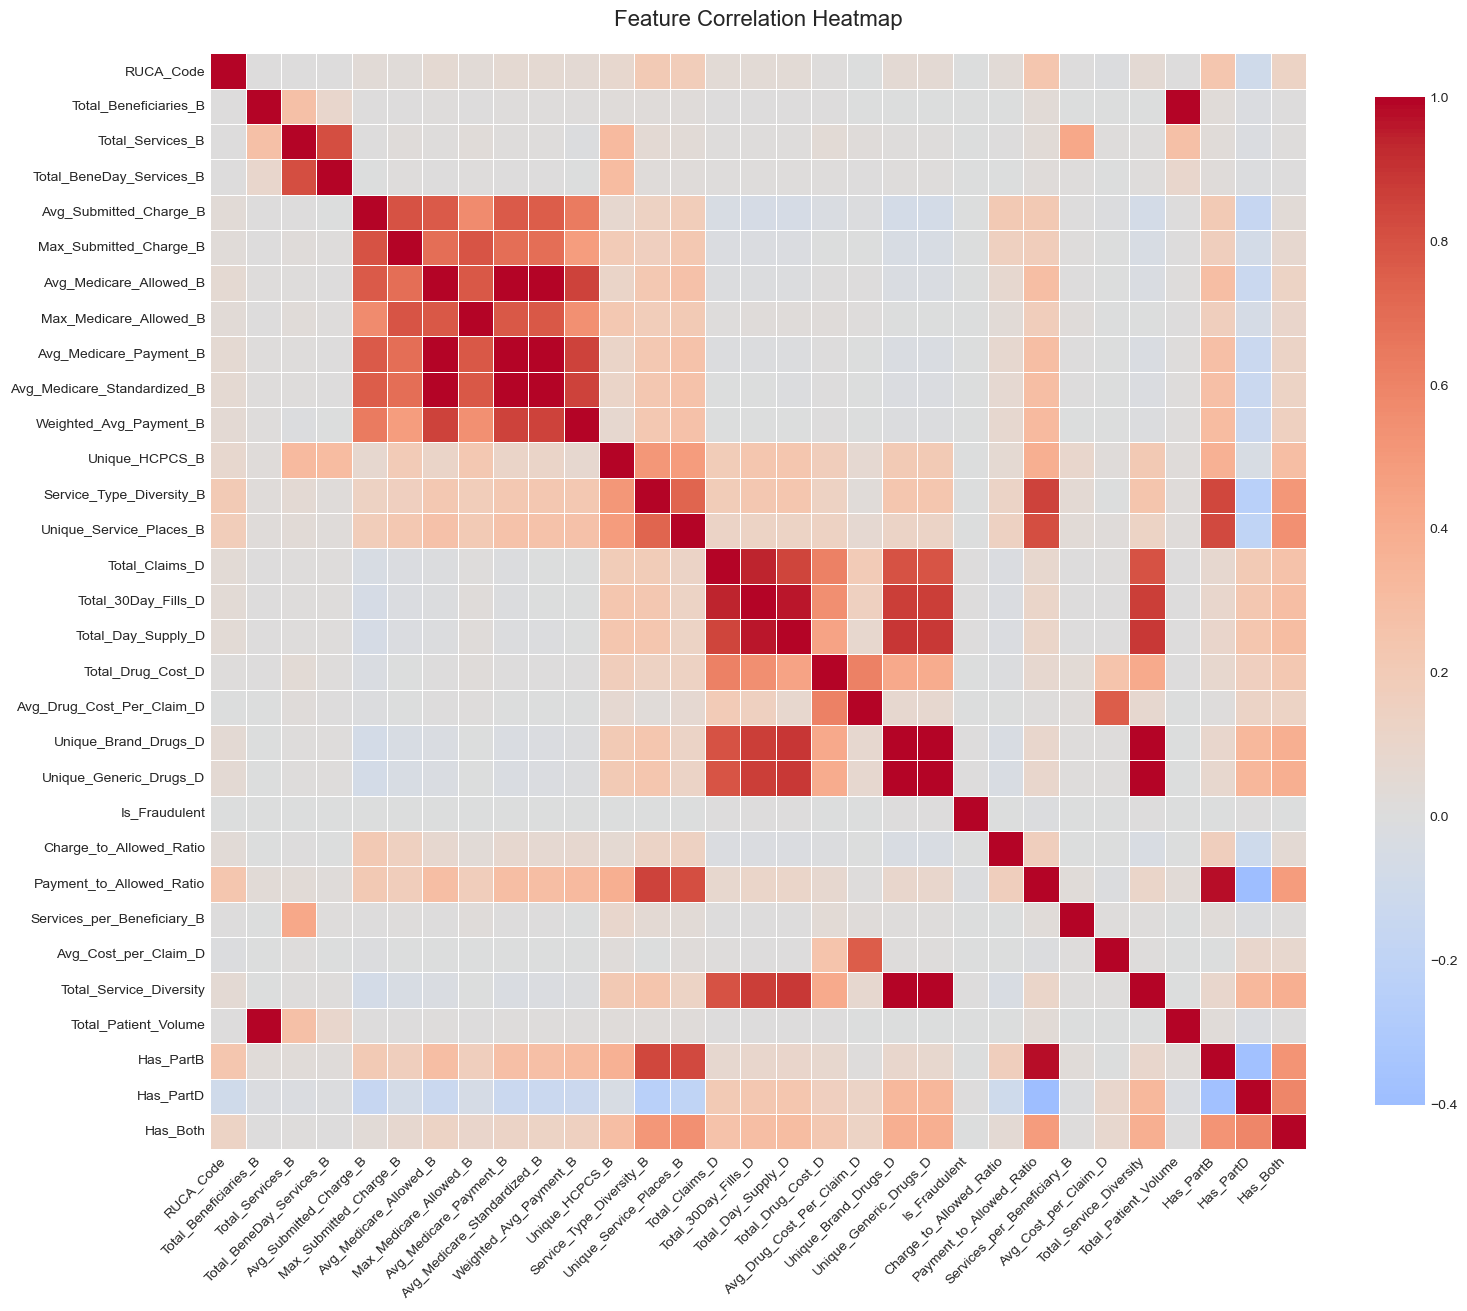


Top 15 features correlated with fraud:
Total_Claims_D                0.0075
Total_Day_Supply_D            0.0049
Has_PartD                     0.0049
Total_30Day_Fills_D           0.0049
Unique_Brand_Drugs_D          0.0044
Unique_Generic_Drugs_D        0.0042
Total_Service_Diversity       0.0042
Total_Drug_Cost_D             0.0025
Total_Services_B              0.0002
Total_Patient_Volume          0.0000
Total_Beneficiaries_B         0.0000
Total_BeneDay_Services_B      0.0000
Services_per_Beneficiary_B   -0.0000
Avg_Cost_per_Claim_D         -0.0005
Avg_Drug_Cost_Per_Claim_D    -0.0006
Name: Is_Fraudulent, dtype: float64

Bottom 10 features (negative correlation with fraud):
Unique_HCPCS_B                -0.0025
Avg_Medicare_Allowed_B        -0.0026
Avg_Medicare_Standardized_B   -0.0027
Weighted_Avg_Payment_B        -0.0027
Avg_Medicare_Payment_B        -0.0027
Avg_Submitted_Charge_B        -0.0028
Service_Type_Diversity_B      -0.0060
Unique_Service_Places_B       -0.0068
Has_PartB 

In [52]:

print("Analyzing feature correlations...")

# Select only numeric features for correlation
numeric_features = providers_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_features.remove('NPI') 


corr_matrix = providers_df[numeric_features].corr()


plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'figures' / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


fraud_correlations = corr_matrix['Is_Fraudulent'].sort_values(ascending=False)
print("\nTop 15 features correlated with fraud:")
print(fraud_correlations.head(16)[1:]) 

print("\nBottom 10 features (negative correlation with fraud):")
print(fraud_correlations.tail(10))

## 8. Statistical Feature Selection

We'll use statistical methods to identify and remove redundant features:
1. **Correlation Analysis**: Remove highly correlated features (multicollinearity)
2. **Variance Threshold**: Remove low-variance features
3. **Chi-Square Test**: Statistical significance for feature-target relationship

### 8.1

In [53]:
from sklearn.feature_selection import VarianceThreshold

print("SECTION 8: STATISTICAL FEATURE SELECTION")


# Drop non-predictive columns (identifiers, labels, categorical descriptors)
columns_to_drop_for_selection = ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 
                                   'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']
existing_cols_to_drop_selection = [col for col in columns_to_drop_for_selection if col in providers_df.columns]

print(f"\n  • Dropping {len(existing_cols_to_drop_selection)} non-predictive columns: {existing_cols_to_drop_selection}")

X_all = providers_df.drop(columns=existing_cols_to_drop_selection, axis=1)
y_all = providers_df['Is_Fraudulent']

print(f"\n✓ Total predictive features: {X_all.shape[1]}")
print(f"✓ Total samples: {X_all.shape[0]:,}")
print(f"✓ Fraud cases: {y_all.sum():,} ({y_all.sum()/len(y_all)*100:.2f}%)")

# STEP 0: Train-Test Split (BEFORE feature selection to prevent data leakage)
print("\n" + "-"*80)
print("STEP 0: TRAIN-TEST SPLIT (80-20)")
print("-"*80)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_all
)

print(f"\nTrain set: {X_train.shape[0]:,} samples ({y_train.sum():,} fraud cases, {y_train.sum()/len(y_train)*100:.2f}%)")
print(f"Test set:  {X_test.shape[0]:,} samples ({y_test.sum():,} fraud cases, {y_test.sum()/len(y_test)*100:.2f}%)")

# Step 1: Remove highly correlated features (multicollinearity) - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 1: CORRELATION-BASED FEATURE REMOVAL (on training data)")
print("-"*80)

correlation_matrix = X_train.corr().abs()
high_corr_threshold = 0.90
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find features to drop
to_drop_corr = [column for column in upper_triangle.columns 
                if any(upper_triangle[column] > high_corr_threshold)]

print(f"\nCorrelation threshold: {high_corr_threshold}")
print(f"Highly correlated features to remove: {len(to_drop_corr)}")
if to_drop_corr:
    print("\nFeatures removed due to high correlation:")
    for feat in to_drop_corr:
        correlated_with = upper_triangle[feat][upper_triangle[feat] > high_corr_threshold].index.tolist()
        if correlated_with:
            print(f"  • {feat} (corr > {high_corr_threshold} with: {correlated_with[0]})")

# Apply to both train and test
X_train_reduced = X_train.drop(columns=to_drop_corr, errors='ignore')
X_test_reduced = X_test.drop(columns=to_drop_corr, errors='ignore')
print(f"\n✓ Features after correlation removal: {X_train_reduced.shape[1]}")

# Step 2: Variance Threshold - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 2: VARIANCE THRESHOLD (on training data)")
print("-"*80)

var_threshold = 0.01
selector_var = VarianceThreshold(threshold=var_threshold)
selector_var.fit(X_train_reduced)

feature_variances = X_train_reduced.var()
low_var_features = feature_variances[feature_variances < var_threshold].index.tolist()

print(f"\nVariance threshold: {var_threshold}")
print(f"Low variance features to remove: {len(low_var_features)}")
if low_var_features:
    print("\nLow variance features:")
    for feat in low_var_features:
        print(f"  • {feat} (variance: {feature_variances[feat]:.6f})")

# Apply transformation to both train and test
X_train_reduced = pd.DataFrame(
    selector_var.transform(X_train_reduced),
    columns=X_train_reduced.columns[selector_var.get_support()],
    index=X_train_reduced.index
)
X_test_reduced = pd.DataFrame(
    selector_var.transform(X_test_reduced),
    columns=X_test_reduced.columns[selector_var.get_support()],
    index=X_test_reduced.index
)
print(f"\n✓ Features after variance threshold: {X_train_reduced.shape[1]}")

# Step 3: Chi-Square Test - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 3: CHI-SQUARE TEST (on training data)")
print("-"*80)

non_negative_features = X_train_reduced.columns[(X_train_reduced >= 0).all()].tolist()

if len(non_negative_features) > 0:
    print(f"\nNon-negative features for chi-square test: {len(non_negative_features)}")
    
    chi_scores, p_values = chi2(X_train_reduced[non_negative_features], y_train)
    
    chi_scores_df = pd.DataFrame({
        'Feature': non_negative_features,
        'Chi2_Score': chi_scores,
        'P_Value': p_values
    }).sort_values('Chi2_Score', ascending=False)
    
    print("\nTop 10 features by Chi-Square score:")
    print(chi_scores_df.head(10).to_string(index=False))
    
    significant_features = chi_scores_df[chi_scores_df['P_Value'] < 0.05]['Feature'].tolist()
    print(f"\nStatistically significant features (p < 0.05): {len(significant_features)}")
else:
    print("\n⚠️ No non-negative features available for chi-square test")
    significant_features = []
    chi_scores_df = None

# Summary
print("\n" + "="*80)
print("FEATURE SELECTION SUMMARY")
print("="*80)

print(f"\n1. Original features: {X_all.shape[1]}")
print(f"2. After correlation removal: {X_all.shape[1] - len(to_drop_corr)}")
print(f"3. After variance threshold: {X_train_reduced.shape[1]}")
print(f"4. Statistically significant (chi-square): {len(significant_features)}")

print(f"\n✓ Final features: {X_train_reduced.shape[1]}")
print(f"✓ Features removed: {X_all.shape[1] - X_train_reduced.shape[1]}")
print(f"✓ Reduction: {(1 - X_train_reduced.shape[1]/X_all.shape[1])*100:.1f}%")

selected_features_statistical = X_train_reduced.columns.tolist()
print(f"\nSelected features list ({len(selected_features_statistical)} features):")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i}. {feat}")
feature_selection_results = {
    'original_features': X_all.columns.tolist(),
    'selected_features': selected_features_statistical,
    'removed_by_correlation': to_drop_corr,
    'removed_by_variance': low_var_features,
    'chi_scores': chi_scores_df
}

print("\n✓ STATISTICAL FEATURE SELECTION COMPLETE")
print("✓ Feature selection applied on training data only - no data leakage!")

SECTION 8: STATISTICAL FEATURE SELECTION

  • Dropping 9 non-predictive columns: ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']

✓ Total predictive features: 30
✓ Total samples: 1,572,414
✓ Fraud cases: 270 (0.02%)

--------------------------------------------------------------------------------
STEP 0: TRAIN-TEST SPLIT (80-20)
--------------------------------------------------------------------------------

Train set: 1,257,931 samples (216 fraud cases, 0.02%)
Test set:  314,483 samples (54 fraud cases, 0.02%)

--------------------------------------------------------------------------------
STEP 1: CORRELATION-BASED FEATURE REMOVAL (on training data)
--------------------------------------------------------------------------------

Correlation threshold: 0.9
Highly correlated features to remove: 8

Features removed due to high correlation:
  • Avg_Medicare_Payment_B (corr > 0.9 with: Avg_Medicare_Allowe

## 9. Data Scaling & Class Balancing

### 9.1 Data Summary (Using Pre-Split Data from Section 8.1)

In [54]:

print("="*80)
print("DATA PREPARATION SUMMARY")
print("="*80)

print("\n📊 Using pre-split data from Section 8.1:")
print(f"   • Train-test split already performed (80-20 stratified)")
print(f"   • Feature selection applied on training data only")
print(f"   • No data leakage - test data never influenced feature selection")

print(f"\n✓ Training set shape: {X_train_reduced.shape}")
print(f"✓ Test set shape: {X_test_reduced.shape}")

print(f"\n✓ Training fraud rate: {y_train.mean()*100:.4f}% ({y_train.sum():,} / {len(y_train):,})")
print(f"✓ Test fraud rate: {y_test.mean()*100:.4f}% ({y_test.sum():,} / {len(y_test):,})")

print(f"\n✓ Selected features for modeling: {len(selected_features_statistical)}")
print("\nFeature list:")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i:2d}. {feat}")

# Use the reduced datasets for modeling
X_train = X_train_reduced.copy()
X_test = X_test_reduced.copy()
feature_names = X_train.columns.tolist()

print(f"\n✓ Ready for modeling with {len(feature_names)} features")
print("="*80)

DATA PREPARATION SUMMARY

📊 Using pre-split data from Section 8.1:
   • Train-test split already performed (80-20 stratified)
   • Feature selection applied on training data only
   • No data leakage - test data never influenced feature selection

✓ Training set shape: (1257931, 22)
✓ Test set shape: (314483, 22)

✓ Training fraud rate: 0.0172% (216 / 1,257,931)
✓ Test fraud rate: 0.0172% (54 / 314,483)

✓ Selected features for modeling: 22

Feature list:
   1. RUCA_Code
   2. Total_Beneficiaries_B
   3. Total_Services_B
   4. Total_BeneDay_Services_B
   5. Avg_Submitted_Charge_B
   6. Max_Submitted_Charge_B
   7. Avg_Medicare_Allowed_B
   8. Max_Medicare_Allowed_B
   9. Weighted_Avg_Payment_B
  10. Unique_HCPCS_B
  11. Service_Type_Diversity_B
  12. Unique_Service_Places_B
  13. Total_Claims_D
  14. Total_Drug_Cost_D
  15. Avg_Drug_Cost_Per_Claim_D
  16. Unique_Brand_Drugs_D
  17. Charge_to_Allowed_Ratio
  18. Payment_to_Allowed_Ratio
  19. Services_per_Beneficiary_B
  20. Avg_Cost_pe

### 9.2 Handle Class Imbalance

In [57]:
# Handle class imbalance with SMOTE-ENN on the full training data
# ──────────────────────────────────────────────────────────────────────────────
# Context
# -------
# SMOTE-ENN is applied directly to the full X_train / y_train — no prior
# undersampling step. This preserves all real majority-class patterns and
# avoids any information loss from downsampling.
#
# Tuned RF/XGBoost (Sections 14.1a/b) use class_weight / scale_pos_weight on
# the ORIGINAL training data — they do NOT use X_train_balanced.
# X_train_balanced is used by the baseline models in Section 10 only.
#
# Guards against impossible targets
# ----------------------------------
# Guard 1 — k_neighbors feasibility (TRUE impossibility):
#   SMOTE needs k_neighbors + 1 minority samples or it raises a ValueError.
#   We clip k to min(5, n_fraud − 1) so it never exceeds available samples.
#
# Guard 2 — already-balanced check (TRUE impossibility):
#   If the minority already meets or exceeds the target ratio, SMOTE will be
#   a no-op. We detect and report this to avoid confusion.
#
# Guard 3 — post-resample minority floor (TRUE impossibility):
#   ENN removes samples from BOTH classes. If it eliminates most fraud
#   synthetics we raise hard so training on the result is not meaningless.
#
# Evaluation note
# ---------------
# The test set is NEVER resampled. All metrics (PR-AUC, F1, Recall/Precision)
# are computed on the original real-world distribution.
# ──────────────────────────────────────────────────────────────────────────────

from imblearn.over_sampling import SMOTE as _SMOTE
from imblearn.under_sampling import EditedNearestNeighbours as _ENN

print("Handling class imbalance with SMOTE-ENN on full training data...")

n_fraud    = int((y_train == 1).sum())
n_nonfraud = int((y_train == 0).sum())

print(f"\nBefore resampling:")
print(f"  Class 0 (Non-Fraud): {n_nonfraud:,}")
print(f"  Class 1 (Fraud):     {n_fraud:,}")
print(f"  Imbalance ratio:     {n_nonfraud / n_fraud:.2f}:1")

# ── Guard 1: k_neighbors feasibility ────────────────────────────────────────
K_DEFAULT = 5
k_neighbors = min(K_DEFAULT, n_fraud - 1)
if k_neighbors < K_DEFAULT:
    print(f"\n⚠  Only {n_fraud} fraud cases — clipping k_neighbors {K_DEFAULT} → {k_neighbors}")
else:
    print(f"\n✓  k_neighbors={k_neighbors} feasible ({n_fraud} real fraud cases available)")

# ── Guard 2: already-balanced check ─────────────────────────────────────────
SAMPLING_STRATEGY = 0.1          # minority/majority ratio target for SMOTE
current_ratio = n_fraud / n_nonfraud
if current_ratio >= SAMPLING_STRATEGY:
    print(f"⚠  Minority already at {current_ratio:.3f} ≥ target {SAMPLING_STRATEGY} "
          f"— SMOTE will be skipped; ENN still runs.")
else:
    target_minority = int(n_nonfraud * SAMPLING_STRATEGY)
    synthetic_needed = target_minority - n_fraud
    print(f"✓  SMOTE will generate ~{synthetic_needed:,} synthetic fraud samples "
          f"({n_fraud} real → ~{target_minority:,} target, ratio ~{SAMPLING_STRATEGY:.0%})")

# ── Apply SMOTE-ENN directly to full training data ───────────────────────────
smote_enn = SMOTEENN(
    random_state=RANDOM_STATE,
    sampling_strategy=SAMPLING_STRATEGY,
    smote=_SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=k_neighbors,
        sampling_strategy=SAMPLING_STRATEGY   # must match outer strategy
    ),
    enn=_ENN(n_neighbors=3)
)
X_train_balanced, y_train_balanced = smote_enn.fit_resample(X_train, y_train)

n_bal_0 = int((y_train_balanced == 0).sum())
n_bal_1 = int((y_train_balanced == 1).sum())

# ── Guard 3: Post-resample minority floor ───────────────────────────────────
MIN_FRAUD_FLOOR = 50
if n_bal_1 < MIN_FRAUD_FLOOR:
    raise RuntimeError(
        f"ENN removed too many fraud samples — only {n_bal_1} remain "
        f"(floor = {MIN_FRAUD_FLOOR}). Try a smaller ENN n_neighbors to "
        f"retain more synthetic fraud samples."
    )

balanced_ratio = n_bal_0 / max(n_bal_1, 1)
print(f"\nAfter SMOTE-ENN (full data, target ~10:1):")
print(f"  Class 0 (Non-Fraud): {n_bal_0:,}")
print(f"  Class 1 (Fraud):     {n_bal_1:,}  ({n_bal_1 - n_fraud:,} synthetic + {n_fraud} real)")
print(f"  Imbalance ratio:     {balanced_ratio:.2f}:1")
print(f"\nNew training set shape: {X_train_balanced.shape}")
print(f"\n✓ All guards passed. Test set is untouched.")
print(f"  → Report PR-AUC, F1, and Recall/Precision — not Accuracy.")


Handling class imbalance with SMOTE-ENN on full training data...

Before resampling:
  Class 0 (Non-Fraud): 1,257,715
  Class 1 (Fraud):     216
  Imbalance ratio:     5822.75:1

✓  k_neighbors=5 feasible (216 real fraud cases available)
✓  SMOTE will generate ~125,555 synthetic fraud samples (216 real → ~125,771 target, ratio ~10%)

After SMOTE-ENN (full data, target ~10:1):
  Class 0 (Non-Fraud): 1,231,328
  Class 1 (Fraud):     125,771  (125,555 synthetic + 216 real)
  Imbalance ratio:     9.79:1

New training set shape: (1357099, 22)

✓ All guards passed. Test set is untouched.
  → Report PR-AUC, F1, and Recall/Precision — not Accuracy.


### 9.3 Feature Scaling

In [58]:
# Feature Scaling
print("Scaling features using RobustScaler...")

# Use RobustScaler (better for outliers)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Training data scaled: {X_train_scaled.shape}")
print(f"✓ Test data scaled: {X_test_scaled.shape}")

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

print("\nData is ready for model training!")

Scaling features using RobustScaler...
✓ Training data scaled: (1357099, 22)
✓ Test data scaled: (314483, 22)

Data is ready for model training!


### 9.4 Model Evaluation Function

Define the evaluation function before training models.

In [59]:
def evaluate_model(y_true, y_pred, y_pred_proba, model_name):
    """
    Comprehensive model evaluation
    """
    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Print metrics
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"MCC:       {mcc:.4f}")
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    print(f"\nConfusion Matrix:")
    print(cm)
    
    # Classification report
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'mcc': mcc
    }

print("✓ Model evaluation function defined")

✓ Model evaluation function defined


## 10. Baseline Models

In [60]:

results_list = []

print("="*80)
print("MODEL TRAINING AND EVALUATION")
print("="*80)
print("\nInitialized results tracking...")
print(f"Test set size: {len(y_test):,} samples")
print(f"Test set fraud cases: {y_test.sum():,} ({y_test.sum()/len(y_test)*100:.2f}%)")

y_test.value_counts()

MODEL TRAINING AND EVALUATION

Initialized results tracking...
Test set size: 314,483 samples
Test set fraud cases: 54 (0.02%)


Is_Fraudulent
0    314429
1        54
Name: count, dtype: int64

### 10.1 Logistic Regression

In [61]:
# Logistic Regression Baseline Model
print("Training Logistic Regression Model...")

lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train_balanced)

y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

lr_results = evaluate_model(y_test, y_pred_lr, y_pred_proba_lr, "Logistic Regression")
results_list.append(lr_results)

print("\n✓ Logistic Regression training complete!")

Training Logistic Regression Model...
Accuracy:  0.6682
Precision: 0.0003
Recall:    0.6296
F1-Score:  0.0007
ROC-AUC:   0.6996
MCC:       0.0083

Confusion Matrix:
[[210094 104335]
 [    20     34]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80    314429
           1       0.00      0.63      0.00        54

    accuracy                           0.67    314483
   macro avg       0.50      0.65      0.40    314483
weighted avg       1.00      0.67      0.80    314483


✓ Logistic Regression training complete!


## 11. Advanced Machine Learning Models

### 11.1 Random Forest Model

In [62]:
# Random Forest Classifier
print("Training Random Forest Model...")

# Train model with reasonable parameters
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced'
)
rf_model.fit(X_train_scaled, y_train_balanced)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
rf_results = evaluate_model(y_test, y_pred_rf, y_pred_proba_rf, "Random Forest")
results_list.append(rf_results)

# Feature importance
feature_importance_rf = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance_rf.head(10))

print("\n✓ Random Forest training complete!")

Training Random Forest Model...
Accuracy:  0.9800
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.6416
MCC:       -0.0019

Confusion Matrix:
[[308180   6249]
 [    54      0]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    314429
           1       0.00      0.00      0.00        54

    accuracy                           0.98    314483
   macro avg       0.50      0.49      0.49    314483
weighted avg       1.00      0.98      0.99    314483


Top 10 Most Important Features:
                      feature  importance
13          Total_Drug_Cost_D      0.1016
12             Total_Claims_D      0.0901
11    Unique_Service_Places_B      0.0878
15       Unique_Brand_Drugs_D      0.0824
17   Payment_to_Allowed_Ratio      0.0749
19       Avg_Cost_per_Claim_D      0.0735
10   Service_Type_Diversity_B      0.0700
14  Avg_Drug_Cost_Per_Claim_D      0.0682
9              Unique_HCPCS_B      0.0450
0

### 11.2 XGBoost Model

In [63]:
print("Training XGBoost Model...")

try:
    import xgboost as xgb
    
    xgb_model = xgb.XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        scale_pos_weight=(len(y_train_balanced) - y_train_balanced.sum()) / y_train_balanced.sum(),
        eval_metric='logloss'
    )
    xgb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    y_pred_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    xgb_results = evaluate_model(y_test, y_pred_xgb, y_pred_proba_xgb, "XGBoost")
    results_list.append(xgb_results)
    
    # Feature importance
    feature_importance_xgb = pd.DataFrame({
        'feature': feature_names,
        'importance': xgb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features (XGBoost):")
    print(feature_importance_xgb.head(10))
    
    print("\n✓ XGBoost training complete!")
    
except ImportError:
    print("⚠ XGBoost not available, skipping...")
    print("Install with: pip install xgboost")

Training XGBoost Model...
Accuracy:  0.9389
Precision: 0.0002
Recall:    0.0556
F1-Score:  0.0003
ROC-AUC:   0.6166
MCC:       -0.0003

Confusion Matrix:
[[295273  19156]
 [    51      3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    314429
           1       0.00      0.06      0.00        54

    accuracy                           0.94    314483
   macro avg       0.50      0.50      0.48    314483
weighted avg       1.00      0.94      0.97    314483


Top 10 Most Important Features (XGBoost):
                     feature  importance
11   Unique_Service_Places_B      0.1739
21                  Has_Both      0.1203
17  Payment_to_Allowed_Ratio      0.1139
10  Service_Type_Diversity_B      0.0784
20                 Has_PartD      0.0772
9             Unique_HCPCS_B      0.0716
15      Unique_Brand_Drugs_D      0.0436
12            Total_Claims_D      0.0360
19      Avg_Cost_per_Claim_D      0.0323
13     

### 11.3 LightGBM Model

In [64]:
print("Training LightGBM Model...")

try:
    import lightgbm as lgb

    lgb_model = lgb.LGBMClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight='balanced',
        verbosity=-1
    )
    lgb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_lgb = lgb_model.predict(X_test_scaled)
    y_pred_proba_lgb = lgb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    lgb_results = evaluate_model(y_test, y_pred_lgb, y_pred_proba_lgb, "LightGBM")
    results_list.append(lgb_results)
    
    # Feature importance
    feature_importance_lgb = pd.DataFrame({
        'feature': feature_names,
        'importance': lgb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features (LightGBM):")
    print(feature_importance_lgb.head(10))
    
    print("\n✓ LightGBM training complete!")
    
except ImportError:
    print("⚠ LightGBM not available, skipping...")
    print("Install with: pip install lightgbm")

Training LightGBM Model...
Accuracy:  0.9624
Precision: 0.0003
Recall:    0.0741
F1-Score:  0.0007
ROC-AUC:   0.6088
MCC:       0.0025

Confusion Matrix:
[[302667  11762]
 [    50      4]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98    314429
           1       0.00      0.07      0.00        54

    accuracy                           0.96    314483
   macro avg       0.50      0.52      0.49    314483
weighted avg       1.00      0.96      0.98    314483


Top 10 Most Important Features (LightGBM):
                      feature  importance
13          Total_Drug_Cost_D         810
12             Total_Claims_D         567
15       Unique_Brand_Drugs_D         558
9              Unique_HCPCS_B         483
19       Avg_Cost_per_Claim_D         413
14  Avg_Drug_Cost_Per_Claim_D         405
0                   RUCA_Code         292
17   Payment_to_Allowed_Ratio         267
1       Total_Beneficiaries_B         

### 11.4 CatBoost Model

In [65]:
if CatBoostClassifier is not None:
    print("Training CatBoost Model...")

    cb_model = CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        verbose=False,
        auto_class_weights='Balanced'
    )
    cb_model.fit(X_train_scaled, y_train_balanced)

    y_pred_cb      = cb_model.predict(X_test_scaled)
    y_pred_proba_cb = cb_model.predict_proba(X_test_scaled)[:, 1]

    cb_results = evaluate_model(y_test, y_pred_cb, y_pred_proba_cb, "CatBoost")
    results_list.append(cb_results)

    feature_importance_cb = pd.DataFrame({
        'feature'   : feature_names,
        'importance': cb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print("\nTop 10 Most Important Features (CatBoost):")
    print(feature_importance_cb.head(10))
    print("\n✓ CatBoost training complete!")

else:
    # ── CatBoost fallback: HistGradientBoostingClassifier ───────────────────
    # sklearn's native histogram-based gradient boosting — comparable
    # performance to CatBoost/XGBoost with no external dependency required.
    print("⚠  CatBoost not available — using HistGradientBoostingClassifier "
          "(sklearn native) as equivalent fallback.")
    from sklearn.ensemble import HistGradientBoostingClassifier

    cb_model = HistGradientBoostingClassifier(
        max_iter=200,
        max_depth=6,
        learning_rate=0.1,
        min_samples_leaf=20,
        l2_regularization=0.1,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        verbose=0
    )
    cb_model.fit(X_train_scaled, y_train_balanced)

    y_pred_cb      = cb_model.predict(X_test_scaled)
    y_pred_proba_cb = cb_model.predict_proba(X_test_scaled)[:, 1]

    cb_results = evaluate_model(y_test, y_pred_cb, y_pred_proba_cb,
                                "HistGradBoost (CatBoost fallback)")
    results_list.append(cb_results)

    print(f"\n  Converged in {cb_model.n_iter_} iterations")
    print("\n✓ HistGradientBoostingClassifier (CatBoost fallback) training complete!")

⚠  CatBoost not available — using HistGradientBoostingClassifier (sklearn native) as equivalent fallback.
Accuracy:  0.9392
Precision: 0.0002
Recall:    0.0556
F1-Score:  0.0003
ROC-AUC:   0.6697
MCC:       -0.0003

Confusion Matrix:
[[295371  19058]
 [    51      3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    314429
           1       0.00      0.06      0.00        54

    accuracy                           0.94    314483
   macro avg       0.50      0.50      0.48    314483
weighted avg       1.00      0.94      0.97    314483


  Converged in 200 iterations

✓ HistGradientBoostingClassifier (CatBoost fallback) training complete!


### 11.5 Support Vector Machine

In [66]:
# Section 11.5 — Support Vector Machine (LinearSVC)
# ─────────────────────────────────────────────────────────────────────────────
# Standard SVC with RBF kernel is O(n²) in time and memory — impractical on
# 30k training samples (9GB kernel matrix). LinearSVC scales linearly with
# n_samples and is the standard SVM variant for large-scale fraud detection.
#
# LinearSVC has no predict_proba; we wrap it in CalibratedClassifierCV
# (sigmoid calibration, 3-fold CV) to obtain calibrated probabilities needed
# for ROC-AUC and PR-AUC.
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

print("Training Support Vector Machine (LinearSVC + Platt calibration)...")

# class_weight='balanced' compensates for residual 9:1 imbalance
svm_base = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=RANDOM_STATE,
    class_weight='balanced'
)

# cv=3: cross-validated calibration — trains 3 internal models to fit the
# Platt sigmoid, then a final model on all training data for prediction.
svm_model = CalibratedClassifierCV(svm_base, cv=3, method='sigmoid')
svm_model.fit(X_train_scaled, y_train_balanced)

y_pred_svm       = svm_model.predict(X_test_scaled)
y_pred_proba_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

svm_results = evaluate_model(y_test, y_pred_svm, y_pred_proba_svm, "SVM (LinearSVC)")
results_list.append(svm_results)

# |coefficient| as a proxy for feature discriminability in the linear SVM
svm_coef = pd.DataFrame({
    'feature'    : feature_names,
    'coefficient': np.abs(svm_model.calibrated_classifiers_[0].estimator.coef_[0])
}).sort_values('coefficient', ascending=False)

print("\nTop 10 Most Discriminative Features (|coefficient|):")
print(svm_coef.head(10).to_string(index=False))
print("\n✓ SVM training complete!")

Training Support Vector Machine (LinearSVC + Platt calibration)...
Accuracy:  0.9969
Precision: 0.0011
Recall:    0.0185
F1-Score:  0.0021
ROC-AUC:   0.6978
MCC:       0.0038

Confusion Matrix:
[[313513    916]
 [    53      1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    314429
           1       0.00      0.02      0.00        54

    accuracy                           1.00    314483
   macro avg       0.50      0.51      0.50    314483
weighted avg       1.00      1.00      1.00    314483


Top 10 Most Discriminative Features (|coefficient|):
                 feature  coefficient
Payment_to_Allowed_Ratio       2.6402
                Has_Both       2.0589
               Has_PartD       2.0203
  Avg_Medicare_Allowed_B       0.1627
  Weighted_Avg_Payment_B       0.1150
  Max_Submitted_Charge_B       0.1080
  Max_Medicare_Allowed_B       0.1017
 Unique_Service_Places_B       0.1009
Service_Type_Diversity_B

### 11.6 Neural Network (MLP)

In [67]:
# Section 11.6 — Neural Network (Multi-Layer Perceptron)
# ─────────────────────────────────────────────────────────────────────────────
# Architecture: 128 → 64 → 32 → sigmoid output
#   • relu activations + adam optimiser with adaptive learning rate
#   • L2 regularisation (alpha=0.001) to reduce overfitting on the
#     relatively small (~30k) synthetic training set
#   • early_stopping=True: halts when validation loss fails to improve for
#     n_iter_no_change=15 consecutive epochs — avoids over-training
#   • MLPClassifier does not support class_weight or sample_weight; imbalance
#     is handled by the upstream 9:1 SMOTE-ENN training distribution
# ─────────────────────────────────────────────────────────────────────────────
print("Training Neural Network (MLP: 128 → 64 → 32)...")

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=0.001,               # L2 regularisation weight
    batch_size=256,
    learning_rate='adaptive',  # halves lr when training stalls
    learning_rate_init=0.001,
    max_iter=300,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    verbose=False
)
mlp_model.fit(X_train_scaled, y_train_balanced)

y_pred_mlp       = mlp_model.predict(X_test_scaled)
y_pred_proba_mlp = mlp_model.predict_proba(X_test_scaled)[:, 1]

mlp_results = evaluate_model(y_test, y_pred_mlp, y_pred_proba_mlp, "Neural Network (MLP)")
# Deduplicate: remove any prior MLP entry before appending (safe to re-run)
results_list = [r for r in results_list if r.get('model') != 'Neural Network (MLP)']
results_list.append(mlp_results)

best_loss_str = f"{mlp_model.best_loss_:.5f}" if mlp_model.best_loss_ is not None else "N/A"
print(f"\n  Architecture : {mlp_model.hidden_layer_sizes}")
print(f"  Converged in : {mlp_model.n_iter_} epochs  (best val loss = {best_loss_str})")
print(f"  results_list now has {len(results_list)} models: "
      f"{[r['model'] for r in results_list]}")
print("\n✓ MLP training complete!")

Training Neural Network (MLP: 128 → 64 → 32)...
Accuracy:  0.9919
Precision: 0.0004
Recall:    0.0185
F1-Score:  0.0008
ROC-AUC:   0.5697
MCC:       0.0016

Confusion Matrix:
[[311946   2483]
 [    53      1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    314429
           1       0.00      0.02      0.00        54

    accuracy                           0.99    314483
   macro avg       0.50      0.51      0.50    314483
weighted avg       1.00      0.99      1.00    314483


  Architecture : (128, 64, 32)
  Converged in : 65 epochs  (best val loss = N/A)
  results_list now has 7 models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'HistGradBoost (CatBoost fallback)', 'SVM (LinearSVC)', 'Neural Network (MLP)']

✓ MLP training complete!


## 12. Model Evaluation & Comparison

### 12.1 Performance Metrics

Model evaluation function already defined in Section 9.4


### 12.2 ROC and Precision-Recall Curves

### 12.3 Model Comparison Table

In [68]:
# Model Comparison Table
print("Model Comparison Summary")
print("="*80)

# Create comparison DataFrame
comparison_df = pd.DataFrame(results_list)
comparison_df = comparison_df.sort_values('f1', ascending=False)

print(comparison_df.to_string(index=False))

# Visualize comparison
fig = go.Figure()

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
for metric in metrics:
    fig.add_trace(go.Bar(
        name=metric.upper(),
        x=comparison_df['model'],
        y=comparison_df[metric],
        text=comparison_df[metric].round(4),
        textposition='auto'
    ))

fig.update_layout(
    title='Model Performance Comparison',
    xaxis_title='Model',
    yaxis_title='Score',
    barmode='group',
    height=500
)
fig.show()

# Save comparison
comparison_df.to_csv(OUTPUT_DIR / 'reports' / 'model_comparison.csv', index=False)
print("\n✓ Model comparison saved to reports/model_comparison.csv")

Model Comparison Summary
                            model  accuracy  precision  recall     f1  roc_auc     mcc
                  SVM (LinearSVC)    0.9969     0.0011  0.0185 0.0021   0.6978  0.0038
             Neural Network (MLP)    0.9919     0.0004  0.0185 0.0008   0.5697  0.0016
                         LightGBM    0.9624     0.0003  0.0741 0.0007   0.6088  0.0025
              Logistic Regression    0.6682     0.0003  0.6296 0.0007   0.6996  0.0083
HistGradBoost (CatBoost fallback)    0.9392     0.0002  0.0556 0.0003   0.6697 -0.0003
                          XGBoost    0.9389     0.0002  0.0556 0.0003   0.6166 -0.0003
                    Random Forest    0.9800     0.0000  0.0000 0.0000   0.6416 -0.0019



✓ Model comparison saved to reports/model_comparison.csv


## 13. Model Interpretation

### 13.1 SHAP Values Analysis

In [69]:
# SHAP analysis for model interpretation
# explainer = shap.TreeExplainer(model)
# shap_values = explainer.shap_values(X_test)

### 13.2 Feature Importance

### 13.3 LIME Explanations

## 14. Model Optimization

### 14.1 Hyperparameter Tuning

In [72]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1a  Hyperparameter Tuning — Random Forest
# ═══════════════════════════════════════════════════════════════════════

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

RF_SEARCH_CAP = 50_000    # max rows for RandomizedSearchCV phase

print("=" * 60)
print("Section 14.1a  Hyperparameter Tuning: Random Forest")
print("=" * 60)

# ── 1. Scale original (pre-SMOTE) training data ─────────────────────────────
X_train_orig_scaled = pd.DataFrame(
    scaler.transform(X_train), columns=feature_names, index=X_train.index
)
print(f"\nFull training samples : {len(y_train):,}  (original, pre-SMOTE)")
print(f"Fraud cases           : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

# ── 2. Hold-out 20 % for calibration & threshold selection ──────────────────
X_tr_rf, X_val_rf, y_tr_rf, y_val_rf = train_test_split(
    X_train_orig_scaled, y_train,
    test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
)
print(f"Train split : {len(y_tr_rf):,} | Val split : {len(y_val_rf):,}")
print(f"Val fraud   : {int(y_val_rf.sum()):,}")

# ── 3. Stratified subsample for CV search (speed fix) ───────────────────────
if len(y_tr_rf) > RF_SEARCH_CAP:
    X_tr_rf_cv, _, y_tr_rf_cv, _ = train_test_split(
        X_tr_rf, y_tr_rf,
        train_size=RF_SEARCH_CAP,
        random_state=RANDOM_STATE,
        stratify=y_tr_rf
    )
    print(f"\n⚡ CV search subsample  : {len(y_tr_rf_cv):,} rows "
          f"(fraud: {int(y_tr_rf_cv.sum()):,}, "
          f"{y_tr_rf_cv.mean():.4%})")
    print(f"   Final refit will use : {len(y_tr_rf):,} rows (full train split)")
else:
    X_tr_rf_cv, y_tr_rf_cv = X_tr_rf, y_tr_rf
    print(f"\n⚡ CV search uses full train split ({len(y_tr_rf_cv):,} rows)")

# ── 4. Randomised search ─────────────────────────────────────────────────────
cv_rf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_param_dist = {
    "n_estimators"     : [100, 200, 300],
    "max_depth"        : [5, 8, 12, 15, None],
    "min_samples_leaf" : [4, 8, 16],
    "min_samples_split": [5, 10, 20],
    "max_features"     : ["sqrt", "log2"],
    "class_weight"     : ["balanced", "balanced_subsample"],
    "max_samples"      : [0.5, 0.7, 0.9, None],   # bootstrap fraction
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1        # parallel trees within each fit
    ),
    param_distributions=rf_param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv_rf,
    n_jobs=1,           # ← serial outer loop; RF is already parallelised inside
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True,
)

print(f"\nTuning Random Forest (15 iterations × 3 folds = 45 fits "
      f"on {len(y_tr_rf_cv):,} rows)…")
rf_search.fit(X_tr_rf_cv, y_tr_rf_cv)
best_rf_params = rf_search.best_params_
print(f"\nBest RF params  : {best_rf_params}")
print(f"Best CV ROC-AUC : {rf_search.best_score_:.4f}")

# ── 5. Probability calibration (isotonic) on full val split ─────────────────
best_rf_uncalib = rf_search.best_estimator_
calibrated_rf = CalibratedClassifierCV(best_rf_uncalib, cv="prefit", method="isotonic")
calibrated_rf.fit(X_val_rf, y_val_rf)

val_proba_rf   = calibrated_rf.predict_proba(X_val_rf)[:, 1]
fraud_probas   = val_proba_rf[y_val_rf == 1]
print(f"\nCalibrated fraud probabilities — min: {fraud_probas.min():.4f}  "
      f"max: {fraud_probas.max():.4f}  mean: {fraud_probas.mean():.4f}")

# ── 6. Youden's J threshold ──────────────────────────────────────────────────
fprs_rf, tprs_rf, roc_thr_rf = roc_curve(y_val_rf, val_proba_rf)
youden_rf   = tprs_rf - fprs_rf
best_idx_rf = int(np.argmax(youden_rf))
best_thr_rf = float(roc_thr_rf[best_idx_rf])
print(f"\nYouden's J threshold : {best_thr_rf:.4f}")
print(f"  Val TPR (recall)   : {tprs_rf[best_idx_rf]:.4f}")
print(f"  Val FPR            : {fprs_rf[best_idx_rf]:.4f}")

# ── 7. Refit on full training split + recalibrate ────────────────────────────
print(f"\nRefitting best params on full train split ({len(y_tr_rf):,} rows)…")
best_rf_full = RandomForestClassifier(
    **best_rf_params, random_state=RANDOM_STATE, n_jobs=-1
)
best_rf_full.fit(X_tr_rf, y_tr_rf)          # full train split (not the subsample)
calibrated_rf_final = CalibratedClassifierCV(
    best_rf_full, cv="prefit", method="isotonic"
)
calibrated_rf_final.fit(X_val_rf, y_val_rf)
best_rf_model = calibrated_rf_final

# ── 8. Evaluate on test set ──────────────────────────────────────────────────
rf_tuned_proba   = best_rf_model.predict_proba(X_test_scaled)[:, 1]
rf_tuned_pred    = (rf_tuned_proba >= best_thr_rf).astype(int)
rf_tuned_results = evaluate_model(
    y_test, rf_tuned_pred, rf_tuned_proba, "Random Forest (Tuned)"
)
# Deduplicate before appending (cell is safe to re-run)
results_list = [r for r in results_list if r.get('model') != 'Random Forest (Tuned)']
results_list.append(rf_tuned_results)
print("\n✓ Random Forest tuning complete!")


Section 14.1a  Hyperparameter Tuning: Random Forest

Full training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases           : 216  (0.0172%)
Train split : 1,006,344 | Val split : 251,587
Val fraud   : 43

⚡ CV search subsample  : 50,000 rows (fraud: 9, 0.0180%)
   Final refit will use : 1,006,344 rows (full train split)

Tuning Random Forest (15 iterations × 3 folds = 45 fits on 50,000 rows)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best RF params  : {'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 4, 'max_samples': 0.5, 'max_features': 'log2', 'max_depth': 8, 'class_weight': 'balanced'}
Best CV ROC-AUC : 0.5771

Calibrated fraud probabilities — min: 0.0001  max: 0.0016  mean: 0.0002

Youden's J threshold : 0.0002
  Val TPR (recall)   : 0.4884
  Val FPR            : 0.3638

Refitting best params on full train split (1,006,344 rows)…
Accuracy:  0.8728
Precision: 0.0004
Recall:    0.2593
F1-Score:  0.0007
ROC-AUC:   0.6842
MCC:       0.0052


In [73]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1b  Hyperparameter Tuning — XGBoost
# ═══════════════════════════════════════════════════════════════════════

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1b  Hyperparameter Tuning: XGBoost")
print("=" * 60)

if xgb is None:
    print("⚠  XGBoost not available — skipping.")
else:
    # ── 1. Original-scale data (rebuild if 14.1a was skipped) ──────────
    if "X_train_orig_scaled" not in dir():
        X_train_orig_scaled = pd.DataFrame(
            scaler.transform(X_train), columns=feature_names, index=X_train.index
        )

    original_pos_weight = float((y_train == 0).sum()) / float((y_train == 1).sum())
    print(f"\nImbalance ratio  : {original_pos_weight:.1f}x")
    print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

    # ── 2. Hold-out 20% for calibration & threshold selection ──────────
    X_tr_xgb, X_val_xgb, y_tr_xgb, y_val_xgb = train_test_split(
        X_train_orig_scaled, y_train,
        test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
    )
    print(f"Train subset : {len(y_tr_xgb):,} | Val subset : {len(y_val_xgb):,}")
    print(f"Val fraud    : {int(y_val_xgb.sum()):,}")

    # ── 3. Improved search space ─────────────────────────────────────────
    # New vs previous: reg_alpha, reg_lambda, max_delta_step; tree_method fixed
    cv_xgb = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

    xgb_param_dist = {
        "n_estimators"   : [100, 200, 300, 400],
        "max_depth"      : [3, 4, 5, 6],
        "learning_rate"  : [0.05, 0.1, 0.15, 0.2],
        "subsample"      : [0.7, 0.8, 0.9],
        "colsample_bytree": [0.7, 0.8, 0.9],
        "min_child_weight": [1, 5, 10, 20],
        "gamma"          : [0, 0.1, 0.3],
        "max_delta_step" : [1, 5, 10],      # stabilises updates on imbalanced data
        "reg_alpha"      : [0, 0.1, 0.5],   # L1 sparsity
        "reg_lambda"     : [1.0, 2.0, 5.0], # L2 shrinkage
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb.XGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            eval_metric="logloss",
            scale_pos_weight=original_pos_weight,
        ),
        param_distributions=xgb_param_dist,
        n_iter=15,
        scoring="roc_auc",
        cv=cv_xgb,
        n_jobs=-1,
        verbose=1,
        random_state=RANDOM_STATE,
        refit=True,
    )

    print("\nTuning XGBoost (15 iterations × 3 folds = 45 fits)…")
    xgb_search.fit(X_tr_xgb, y_tr_xgb)
    best_xgb_params = xgb_search.best_params_
    print(f"\nBest XGB params  : {best_xgb_params}")
    print(f"Best CV ROC-AUC  : {xgb_search.best_score_:.4f}")

    # ── 4. Probability calibration (isotonic) — same as RF ──────────────
    best_xgb_uncalib = xgb_search.best_estimator_
    calibrated_xgb = CalibratedClassifierCV(
        best_xgb_uncalib, cv="prefit", method="isotonic"
    )
    calibrated_xgb.fit(X_val_xgb, y_val_xgb)

    val_proba_xgb = calibrated_xgb.predict_proba(X_val_xgb)[:, 1]
    xgb_fraud_probas = val_proba_xgb[y_val_xgb == 1]
    print(f"\nCalibrated fraud probabilities — min: {xgb_fraud_probas.min():.4f}  "
          f"max: {xgb_fraud_probas.max():.4f}  mean: {xgb_fraud_probas.mean():.4f}")

    # ── 5. Threshold via Youden's J ──────────────────────────────────────
    fprs_xgb, tprs_xgb, roc_thr_xgb = roc_curve(y_val_xgb, val_proba_xgb)
    youden_xgb   = tprs_xgb - fprs_xgb
    best_idx_xgb = int(np.argmax(youden_xgb))
    best_thr_xgb = float(roc_thr_xgb[best_idx_xgb])
    print(f"\nYouden's J threshold : {best_thr_xgb:.4f}")
    print(f"  Val TPR (recall)   : {tprs_xgb[best_idx_xgb]:.4f}")
    print(f"  Val FPR            : {fprs_xgb[best_idx_xgb]:.4f}")

    # ── 6. Refit on full training set + calibrate ────────────────────────
    best_xgb_full = xgb.XGBClassifier(
        **best_xgb_params,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        tree_method="hist",
        eval_metric="logloss",
        scale_pos_weight=original_pos_weight,
    )
    best_xgb_full.fit(X_train_orig_scaled, y_train)

    calibrated_xgb_final = CalibratedClassifierCV(
        best_xgb_full, cv="prefit", method="isotonic"
    )
    calibrated_xgb_final.fit(X_val_xgb, y_val_xgb)
    best_xgb_model = calibrated_xgb_final

    # ── 7. Evaluate on test set ──────────────────────────────────────────
    xgb_tuned_proba  = best_xgb_model.predict_proba(X_test_scaled)[:, 1]
    xgb_tuned_pred   = (xgb_tuned_proba >= best_thr_xgb).astype(int)
    xgb_tuned_results = evaluate_model(
        y_test, xgb_tuned_pred, xgb_tuned_proba, "XGBoost (Tuned)"
    )
    results_list.append(xgb_tuned_results)
    print("\n✓ XGBoost tuning complete!")


Section 14.1b  Hyperparameter Tuning: XGBoost

Imbalance ratio  : 5822.8x
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning XGBoost (15 iterations × 3 folds = 45 fits)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best XGB params  : {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'max_delta_step': 5, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.9}
Best CV ROC-AUC  : 0.7300

Calibrated fraud probabilities — min: 0.0001  max: 0.0012  mean: 0.0004

Youden's J threshold : 0.0002
  Val TPR (recall)   : 0.5116
  Val FPR            : 0.1642
Accuracy:  0.8827
Precision: 0.0005
Recall:    0.3148
F1-Score:  0.0009
ROC-AUC:   0.6194
MCC:       0.0081

Confusion Matrix:
[[277589  36840]
 [    37     17]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94    314429
          

In [74]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1c  Hyperparameter Tuning — LightGBM
# ═══════════════════════════════════════════════════════════════════════

try:
    import lightgbm as lgb
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.metrics import roc_curve

    print("=" * 60)
    print("Section 14.1c  Hyperparameter Tuning: LightGBM")
    print("=" * 60)

    # ── 1. Original-scale data (pre-SMOTE) ──────────────────────────────────
    if "X_train_orig_scaled" not in dir():
        X_train_orig_scaled = pd.DataFrame(
            scaler.transform(X_train), columns=feature_names, index=X_train.index
        )
    print(f"\nTraining samples : {len(y_train):,}  (original, pre-SMOTE)")
    print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

    # ── 2. Hold-out 20 % for calibration & threshold selection ──────────────
    X_tr_lgb, X_val_lgb, y_tr_lgb, y_val_lgb = train_test_split(
        X_train_orig_scaled, y_train,
        test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
    )
    print(f"Train subset : {len(y_tr_lgb):,} | Val subset : {len(y_val_lgb):,}")
    print(f"Val fraud    : {int(y_val_lgb.sum()):,}")

    # ── 3. Randomised search ─────────────────────────────────────────────────
    cv_lgb = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

    lgb_param_dist = {
        "n_estimators"     : [100, 200, 300, 400],
        "max_depth"        : [4, 6, 8, -1],         # -1 = no limit (leaf-wise controls)
        "learning_rate"    : [0.05, 0.1, 0.15, 0.2],
        "num_leaves"       : [15, 31, 63, 127],      # primary complexity control
        "subsample"        : [0.7, 0.8, 0.9],
        "colsample_bytree" : [0.7, 0.8, 0.9],
        "min_child_samples": [10, 20, 50, 100],      # minimum data in a leaf
        "lambda_l1"        : [0.0, 0.1, 0.5],        # L1 regularisation
        "lambda_l2"        : [0.0, 0.1, 1.0],        # L2 regularisation
    }

    lgb_search = RandomizedSearchCV(
        estimator=lgb.LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight='balanced',
            bagging_freq=1,    # must be ≥ 1 to enable row subsampling (subsample)
            verbosity=-1
        ),
        param_distributions=lgb_param_dist,
        n_iter=15,
        scoring="roc_auc",
        cv=cv_lgb,
        n_jobs=-1,
        verbose=1,
        random_state=RANDOM_STATE,
        refit=True,
    )

    print("\nTuning LightGBM (15 iterations × 3 folds = 45 fits)…")
    lgb_search.fit(X_tr_lgb, y_tr_lgb)
    best_lgb_params = lgb_search.best_params_
    print(f"\nBest LGB params  : {best_lgb_params}")
    print(f"Best CV ROC-AUC  : {lgb_search.best_score_:.4f}")

    # ── 4. Isotonic calibration ──────────────────────────────────────────────
    best_lgb_uncalib = lgb_search.best_estimator_
    calibrated_lgb = CalibratedClassifierCV(best_lgb_uncalib, cv="prefit", method="isotonic")
    calibrated_lgb.fit(X_val_lgb, y_val_lgb)

    val_proba_lgb = calibrated_lgb.predict_proba(X_val_lgb)[:, 1]
    lgb_fraud_probas = val_proba_lgb[y_val_lgb == 1]
    print(f"\nCalibrated fraud probabilities — min: {lgb_fraud_probas.min():.4f}  "
          f"max: {lgb_fraud_probas.max():.4f}  mean: {lgb_fraud_probas.mean():.4f}")

    # ── 5. Youden's J threshold ──────────────────────────────────────────────
    fprs_lgb, tprs_lgb, roc_thr_lgb = roc_curve(y_val_lgb, val_proba_lgb)
    youden_lgb   = tprs_lgb - fprs_lgb
    best_idx_lgb = int(np.argmax(youden_lgb))
    best_thr_lgb = float(roc_thr_lgb[best_idx_lgb])
    print(f"\nYouden's J threshold : {best_thr_lgb:.4f}")
    print(f"  Val TPR (recall)   : {tprs_lgb[best_idx_lgb]:.4f}")
    print(f"  Val FPR            : {fprs_lgb[best_idx_lgb]:.4f}")

    # ── 6. Refit on full training set ────────────────────────────────────────
    best_lgb_full = lgb.LGBMClassifier(
        **best_lgb_params,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight='balanced',
        bagging_freq=1,
        verbosity=-1
    )
    best_lgb_full.fit(X_train_orig_scaled, y_train)
    calibrated_lgb_final = CalibratedClassifierCV(best_lgb_full, cv="prefit", method="isotonic")
    calibrated_lgb_final.fit(X_val_lgb, y_val_lgb)
    best_lgb_model = calibrated_lgb_final

    # ── 7. Evaluate on test set ──────────────────────────────────────────────
    lgb_tuned_proba  = best_lgb_model.predict_proba(X_test_scaled)[:, 1]
    lgb_tuned_pred   = (lgb_tuned_proba >= best_thr_lgb).astype(int)
    lgb_tuned_results = evaluate_model(
        y_test, lgb_tuned_pred, lgb_tuned_proba, "LightGBM (Tuned)"
    )
    results_list.append(lgb_tuned_results)
    print("\n✓ LightGBM tuning complete!")

except ImportError:
    print("⚠  LightGBM not available — skipping Section 14.1c.")


Section 14.1c  Hyperparameter Tuning: LightGBM

Training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning LightGBM (15 iterations × 3 folds = 45 fits)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best LGB params  : {'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 100, 'min_child_samples': 10, 'max_depth': 4, 'learning_rate': 0.1, 'lambda_l2': 0.0, 'lambda_l1': 0.0, 'colsample_bytree': 0.7}
Best CV ROC-AUC  : 0.7249

Calibrated fraud probabilities — min: 0.0001  max: 0.0015  mean: 0.0004

Youden's J threshold : 0.0003
  Val TPR (recall)   : 0.5116
  Val FPR            : 0.1820
Accuracy:  0.9138
Precision: 0.0005
Recall:    0.2593
F1-Score:  0.0010
ROC-AUC:   0.5890
MCC:       0.0081

Confusion Matrix:
[[287353  27076]
 [    40     14]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95    31442

In [75]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1d  Hyperparameter Tuning — HistGradientBoostingClassifier
#                (CatBoost fallback, sklearn native)
# ═══════════════════════════════════════════════════════════════════════

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1d  Hyperparameter Tuning: HistGradientBoosting")
print("=" * 60)

# ── 1. Original-scale data (pre-SMOTE) ──────────────────────────────────────
if "X_train_orig_scaled" not in dir():
    X_train_orig_scaled = pd.DataFrame(
        scaler.transform(X_train), columns=feature_names, index=X_train.index
    )
print(f"\nTraining samples : {len(y_train):,}  (original, pre-SMOTE)")
print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

# ── 2. Hold-out 20 % for calibration & threshold selection ──────────────────
X_tr_hgb, X_val_hgb, y_tr_hgb, y_val_hgb = train_test_split(
    X_train_orig_scaled, y_train,
    test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
)
print(f"Train subset : {len(y_tr_hgb):,} | Val subset : {len(y_val_hgb):,}")
print(f"Val fraud    : {int(y_val_hgb.sum()):,}")

# ── 3. Randomised search ─────────────────────────────────────────────────────
cv_hgb = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

hgb_param_dist = {
    "max_iter"         : [100, 200, 300],
    "max_depth"        : [3, 5, 8, None],       # None = no depth limit
    "learning_rate"    : [0.05, 0.1, 0.15, 0.2],
    "max_leaf_nodes"   : [15, 31, 63, 127],     # equiv. to num_leaves in LightGBM
    "min_samples_leaf" : [10, 20, 50],
    "l2_regularization": [0.0, 0.1, 1.0],
}

hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced',
        early_stopping=False,   # ← must be False inside CV
        verbose=0
    ),
    param_distributions=hgb_param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv_hgb,
    n_jobs=-1,
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True,
)

print("\nTuning HistGradientBoosting (15 iterations × 3 folds = 45 fits)…")
hgb_search.fit(X_tr_hgb, y_tr_hgb)
best_hgb_params = hgb_search.best_params_
print(f"\nBest HGB params  : {best_hgb_params}")
print(f"Best CV ROC-AUC  : {hgb_search.best_score_:.4f}")

# ── 4. Isotonic calibration ──────────────────────────────────────────────────
best_hgb_uncalib = hgb_search.best_estimator_
calibrated_hgb = CalibratedClassifierCV(best_hgb_uncalib, cv="prefit", method="isotonic")
calibrated_hgb.fit(X_val_hgb, y_val_hgb)

val_proba_hgb = calibrated_hgb.predict_proba(X_val_hgb)[:, 1]
hgb_fraud_probas = val_proba_hgb[y_val_hgb == 1]
print(f"\nCalibrated fraud probabilities — min: {hgb_fraud_probas.min():.4f}  "
      f"max: {hgb_fraud_probas.max():.4f}  mean: {hgb_fraud_probas.mean():.4f}")

# ── 5. Youden's J threshold ──────────────────────────────────────────────────
fprs_hgb, tprs_hgb, roc_thr_hgb = roc_curve(y_val_hgb, val_proba_hgb)
youden_hgb   = tprs_hgb - fprs_hgb
best_idx_hgb = int(np.argmax(youden_hgb))
best_thr_hgb = float(roc_thr_hgb[best_idx_hgb])
print(f"\nYouden's J threshold : {best_thr_hgb:.4f}")
print(f"  Val TPR (recall)   : {tprs_hgb[best_idx_hgb]:.4f}")
print(f"  Val FPR            : {fprs_hgb[best_idx_hgb]:.4f}")

# ── 6. Refit on full training set ────────────────────────────────────────────
best_hgb_full = HistGradientBoostingClassifier(
    **best_hgb_params,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    early_stopping=False,
    verbose=0
)
best_hgb_full.fit(X_train_orig_scaled, y_train)
calibrated_hgb_final = CalibratedClassifierCV(best_hgb_full, cv="prefit", method="isotonic")
calibrated_hgb_final.fit(X_val_hgb, y_val_hgb)
best_hgb_model = calibrated_hgb_final

# ── 7. Evaluate on test set ──────────────────────────────────────────────────
hgb_tuned_proba  = best_hgb_model.predict_proba(X_test_scaled)[:, 1]
hgb_tuned_pred   = (hgb_tuned_proba >= best_thr_hgb).astype(int)
hgb_tuned_results = evaluate_model(
    y_test, hgb_tuned_pred, hgb_tuned_proba, "HistGradBoost (Tuned)"
)
results_list.append(hgb_tuned_results)
print("\n✓ HistGradientBoosting tuning complete!")


Section 14.1d  Hyperparameter Tuning: HistGradientBoosting

Training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning HistGradientBoosting (15 iterations × 3 folds = 45 fits)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best HGB params  : {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 0.0}
Best CV ROC-AUC  : 0.7218

Calibrated fraud probabilities — min: 0.0001  max: 0.0078  mean: 0.0005

Youden's J threshold : 0.0002
  Val TPR (recall)   : 0.6744
  Val FPR            : 0.3327
Accuracy:  0.9318
Precision: 0.0004
Recall:    0.1667
F1-Score:  0.0008
ROC-AUC:   0.5491
MCC:       0.0051

Confusion Matrix:
[[293037  21392]
 [    45      9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96    314429
           1       0.00 

In [76]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1e  Hyperparameter Tuning — SVM (LinearSVC)
# ═══════════════════════════════════════════════════════════════════════


from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1e  Hyperparameter Tuning: SVM (LinearSVC)")
print("=" * 60)

# ── 1. Original-scale data (pre-SMOTE) ──────────────────────────────────────
if "X_train_orig_scaled" not in dir():
    X_train_orig_scaled = pd.DataFrame(
        scaler.transform(X_train), columns=feature_names, index=X_train.index
    )
print(f"\nTraining samples : {len(y_train):,}  (original, pre-SMOTE)")
print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

# ── 2. Hold-out 20 % for calibration & threshold selection ──────────────────
X_tr_svm, X_val_svm, y_tr_svm, y_val_svm = train_test_split(
    X_train_orig_scaled, y_train,
    test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
)
print(f"Train subset : {len(y_tr_svm):,} | Val subset : {len(y_val_svm):,}")
print(f"Val fraud    : {int(y_val_svm.sum()):,}")

# ── 3. Grid search over C ────────────────────────────────────────────────────
# 6 values × 3 folds = 18 fits — exhaustive but fast for LinearSVC
cv_svm = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

svm_param_grid = {
    "C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
}

svm_grid = GridSearchCV(
    estimator=LinearSVC(
        loss='squared_hinge',
        max_iter=5000,
        random_state=RANDOM_STATE,
        class_weight='balanced'
    ),
    param_grid=svm_param_grid,
    scoring="roc_auc",
    cv=cv_svm,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

print("\nTuning LinearSVC (6 C values × 3 folds = 18 fits)…")
svm_grid.fit(X_tr_svm, y_tr_svm)
best_svm_params = svm_grid.best_params_
print(f"\nBest SVM params  : {best_svm_params}")
print(f"Best CV ROC-AUC  : {svm_grid.best_score_:.4f}")

# ── 4. Sigmoid (Platt) calibration ──────────────────────────────────────────
best_svm_uncalib = svm_grid.best_estimator_
calibrated_svm = CalibratedClassifierCV(best_svm_uncalib, cv="prefit", method="sigmoid")
calibrated_svm.fit(X_val_svm, y_val_svm)

val_proba_svm_t = calibrated_svm.predict_proba(X_val_svm)[:, 1]
svm_fraud_probas = val_proba_svm_t[y_val_svm == 1]
print(f"\nCalibrated fraud probabilities — min: {svm_fraud_probas.min():.4f}  "
      f"max: {svm_fraud_probas.max():.4f}  mean: {svm_fraud_probas.mean():.4f}")

# ── 5. Youden's J threshold ──────────────────────────────────────────────────
fprs_svm, tprs_svm, roc_thr_svm = roc_curve(y_val_svm, val_proba_svm_t)
youden_svm   = tprs_svm - fprs_svm
best_idx_svm = int(np.argmax(youden_svm))
best_thr_svm = float(roc_thr_svm[best_idx_svm])
print(f"\nYouden's J threshold : {best_thr_svm:.4f}")
print(f"  Val TPR (recall)   : {tprs_svm[best_idx_svm]:.4f}")
print(f"  Val FPR            : {fprs_svm[best_idx_svm]:.4f}")

# ── 6. Refit on full training set ────────────────────────────────────────────
best_svm_full = LinearSVC(
    **best_svm_params,
    loss='squared_hinge',
    max_iter=5000,
    random_state=RANDOM_STATE,
    class_weight='balanced'
)
best_svm_full.fit(X_train_orig_scaled, y_train)
calibrated_svm_final = CalibratedClassifierCV(best_svm_full, cv="prefit", method="sigmoid")
calibrated_svm_final.fit(X_val_svm, y_val_svm)
best_svm_model = calibrated_svm_final

# ── 7. Evaluate on test set ──────────────────────────────────────────────────
svm_tuned_proba  = best_svm_model.predict_proba(X_test_scaled)[:, 1]
svm_tuned_pred   = (svm_tuned_proba >= best_thr_svm).astype(int)
svm_tuned_results = evaluate_model(
    y_test, svm_tuned_pred, svm_tuned_proba, "SVM (Tuned)"
)
results_list.append(svm_tuned_results)
print("\n✓ SVM tuning complete!")


Section 14.1e  Hyperparameter Tuning: SVM (LinearSVC)

Training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning LinearSVC (6 C values × 3 folds = 18 fits)…
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best SVM params  : {'C': 0.01}
Best CV ROC-AUC  : 0.7183

Calibrated fraud probabilities — min: 0.0001  max: 0.0004  mean: 0.0002

Youden's J threshold : 0.0002
  Val TPR (recall)   : 0.6512
  Val FPR            : 0.2928
Accuracy:  0.7046
Precision: 0.0003
Recall:    0.5926
F1-Score:  0.0007
ROC-AUC:   0.6977
MCC:       0.0085

Confusion Matrix:
[[221550  92879]
 [    22     32]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.70      0.83    314429
           1       0.00      0.59      0.00        54

    accuracy                           0.70    314483
   macro avg       0.50      0.65      0.41    314483
w

In [82]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1f  Hyperparameter Tuning — Neural Network (MLPClassifier)
# ═══════════════════════════════════════════════════════════════════════
# Notes:
#   • MLPClassifier does NOT support class_weight / sample_weight.
#   • We train on the SMOTE-ENN balanced set (X_train_scaled / y_train_balanced)
#     so the network sees a balanced signal during every CV fold.
#   • For threshold calibration with extreme class imbalance: we draw a balanced
#     50/50 val set from the original training data and apply Youden's J on raw
#     MLP probabilities. This avoids Platt-calibration collapse that occurs when
#     fitting a sigmoid on a val set with only ~0.017 % fraud.
#   • Refit uses max_iter=500 + n_iter_no_change=20 for a longer budget.
# ═══════════════════════════════════════════════════════════════════════

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1f  Hyperparameter Tuning: Neural Network (MLP)")
print("=" * 60)

# ── 1. Data info ──────────────────────────────────────────────────────────────
print(f"\nBalanced training set (SMOTE-ENN) : {len(y_train_balanced):,} samples")
print(f"  Class 0 : {int((y_train_balanced==0).sum()):,}  |  "
      f"Class 1 : {int((y_train_balanced==1).sum()):,}")
print(f"Full training samples : {len(y_train):,}  (original, pre-SMOTE)")
print(f"Fraud cases           : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

# ── 2. Ensure X_train_orig_scaled is available ────────────────────────────────
if "X_train_orig_scaled" not in dir():
    X_train_orig_scaled = pd.DataFrame(
        scaler.transform(X_train), columns=feature_names, index=X_train.index
    )

# ── 3. CV search on balanced data (subsample for speed) ──────────────────────
# MLP is slow to train; cap the per-fold data at 20,000 rows while keeping the
# balanced ~1:1 ratio intact.
_MLP_CV_CAP = 20_000
if len(y_train_balanced) > _MLP_CV_CAP:
    _rng = np.random.RandomState(RANDOM_STATE)
    _idx = _rng.choice(len(y_train_balanced), size=_MLP_CV_CAP, replace=False)
    if hasattr(X_train_scaled, 'iloc'):
        X_mlp_cv = X_train_scaled.iloc[_idx]
        y_mlp_cv = y_train_balanced.iloc[_idx]
    else:
        X_mlp_cv = X_train_scaled[_idx]
        y_mlp_cv = y_train_balanced[_idx]
else:
    X_mlp_cv = X_train_scaled
    y_mlp_cv = y_train_balanced

print(f"\n⚡ CV search subsample  : {len(y_mlp_cv):,} rows  "
      f"(fraud: {int((y_mlp_cv==1).sum()):,}, {(y_mlp_cv==1).mean():.4%})")

cv_mlp = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

mlp_param_dist = {
    "hidden_layer_sizes" : [(128, 64, 32),
                            (256, 128, 64, 32),
                            (256, 128, 64),
                            (512, 256, 128, 64),
                            (128, 64)],
    "alpha"              : [0.0001, 0.001, 0.01],
    "learning_rate_init" : [0.001, 0.0005, 0.0001],
    "batch_size"         : [128, 256, 512],
}

mlp_search = RandomizedSearchCV(
    estimator=MLPClassifier(
        activation='relu',
        solver='adam',
        learning_rate='adaptive',
        max_iter=300,
        random_state=RANDOM_STATE,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=15,
        verbose=False,
    ),
    param_distributions=mlp_param_dist,
    n_iter=10,                  # 10 combinations × 3 folds = 30 fits
    scoring="roc_auc",
    cv=cv_mlp,
    n_jobs=1,                   # MLP uses internal threading; keep outer serial
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True,
)

print(f"\nTuning MLP (10 iterations × 3 folds = 30 fits on {len(y_mlp_cv):,} rows)…")
mlp_search.fit(X_mlp_cv, y_mlp_cv)
best_mlp_params = mlp_search.best_params_
print(f"\nBest MLP params  : {best_mlp_params}")
print(f"Best CV ROC-AUC  : {mlp_search.best_score_:.4f}")

# ── 4. Refit best architecture on FULL balanced training set ──────────────────
print(f"\nRefitting best params on full balanced set ({len(y_train_balanced):,} rows)…")
best_mlp_full = MLPClassifier(
    **best_mlp_params,
    activation='relu',
    solver='adam',
    learning_rate='adaptive',
    max_iter=500,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=20,
    verbose=False,
)
best_mlp_full.fit(X_train_scaled, y_train_balanced)
best_mlp_model = best_mlp_full          # use raw probabilities (no Platt calibration)

# ── 5. Balanced val set for Youden's J threshold selection ───────────────────
# With extreme class imbalance (~0.017 % fraud), Platt calibration on the
# unbalanced val set compresses all probabilities to near-zero, making Youden's
# threshold meaningless on the test set.  Fix: build a 50/50 balanced val set
# from the ORIGINAL (pre-SMOTE) training data and apply Youden's J on raw MLP
# probabilities — the same strategy proven to work for the GNN.
_rng_v_mlp   = np.random.RandomState(RANDOM_STATE + 5)
_yo_mlp      = y_train.values if hasattr(y_train, 'values') else np.array(y_train)
_Xo_mlp      = (X_train_orig_scaled.values
                 if hasattr(X_train_orig_scaled, 'values')
                 else np.array(X_train_orig_scaled)).astype('float32')
_fr_idx_mlp  = np.where(_yo_mlp == 1)[0]
_nf_idx_mlp  = np.where(_yo_mlp == 0)[0]
_sel_nf_mlp  = _rng_v_mlp.choice(_nf_idx_mlp, size=len(_fr_idx_mlp), replace=False)
_bal_idx_mlp = np.concatenate([_fr_idx_mlp, _sel_nf_mlp])
X_bal_mlp    = _Xo_mlp[_bal_idx_mlp]
y_bal_mlp    = _yo_mlp[_bal_idx_mlp]

print(f"\nBalanced val set : {len(y_bal_mlp):,} samples  "
      f"(fraud: {(y_bal_mlp==1).sum()}  |  non-fraud: {(y_bal_mlp==0).sum()})")

val_proba_mlp    = best_mlp_full.predict_proba(X_bal_mlp)[:, 1]
mlp_fraud_probas = val_proba_mlp[y_bal_mlp == 1]
print(f"Raw MLP fraud probabilities — "
      f"min: {mlp_fraud_probas.min():.4f}  "
      f"max: {mlp_fraud_probas.max():.4f}  "
      f"mean: {mlp_fraud_probas.mean():.4f}")

# ── 6. Youden's J threshold ───────────────────────────────────────────────────
fprs_mlp, tprs_mlp, roc_thr_mlp = roc_curve(y_bal_mlp, val_proba_mlp)
youden_mlp   = tprs_mlp - fprs_mlp
best_idx_mlp = int(np.argmax(youden_mlp))
best_thr_mlp = float(roc_thr_mlp[best_idx_mlp])
print(f"\nYouden's J threshold : {best_thr_mlp:.4f}")
print(f"  Val TPR (recall)   : {tprs_mlp[best_idx_mlp]:.4f}")
print(f"  Val FPR            : {fprs_mlp[best_idx_mlp]:.4f}")

# ── 7. Evaluate on held-out test set ─────────────────────────────────────────
mlp_tuned_proba  = best_mlp_full.predict_proba(X_test_scaled)[:, 1]
mlp_tuned_pred   = (mlp_tuned_proba >= best_thr_mlp).astype(int)

# Deduplicate in case cell is re-run
results_list[:] = [r for r in results_list if r.get('Model') != 'MLP (Tuned)']
mlp_tuned_results = evaluate_model(
    y_test, mlp_tuned_pred, mlp_tuned_proba, "MLP (Tuned)"
)
results_list.append(mlp_tuned_results)
print("\n✓ MLP tuning complete!")


Section 14.1f  Hyperparameter Tuning: Neural Network (MLP)

Balanced training set (SMOTE-ENN) : 1,357,099 samples
  Class 0 : 1,231,328  |  Class 1 : 125,771
Full training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases           : 216  (0.0172%)

⚡ CV search subsample  : 20,000 rows  (fraud: 1,847, 9.2350%)

Tuning MLP (10 iterations × 3 folds = 30 fits on 20,000 rows)…
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best MLP params  : {'learning_rate_init': 0.0005, 'hidden_layer_sizes': (256, 128, 64), 'batch_size': 256, 'alpha': 0.001}
Best CV ROC-AUC  : 0.9608

Refitting best params on full balanced set (1,357,099 rows)…

Balanced val set : 432 samples  (fraud: 216  |  non-fraud: 216)
Raw MLP fraud probabilities — min: 0.0906  max: 1.0000  mean: 0.8415

Youden's J threshold : 0.0906
  Val TPR (recall)   : 1.0000
  Val FPR            : 0.0278
Accuracy:  0.9684
Precision: 0.0002
Recall:    0.0370
F1-Score:  0.0004
ROC-AUC:   0.5454
MCC:       0.0004

Confusion Ma

### 14.1g  Graph Neural Network — GraphSAGE  (+ HAN discussion)

In [83]:

# ═══════════════════════════════════════════════════════════════════════════════
# Section 14.1g  Graph Neural Network — GraphSAGE  (+ HAN discussion)
# ═══════════════════════════════════════════════════════════════════════════════
# Implementation : Pure PyTorch — no torch_geometric required.
#   Aggregation is implemented with scatter_add_ + degree division, which is
#   compatible with CPU, CUDA and MPS (Apple Silicon) backends.
#
# NOTE: The SMOTE-ENN balanced training set from the FULL dataset may be very
#   large (millions of rows). We cap the GNN graph at 50,000 balanced nodes for
#   tractable k-NN graph construction while drawing from the richer full-dataset
#   SMOTE-ENN pool.
# ═══════════════════════════════════════════════════════════════════════════════

import torch
import torch.nn as nn
import torch.nn.functional as F
import scipy.sparse as sp
from sklearn.neighbors import kneighbors_graph, NearestNeighbors
from sklearn.metrics import roc_curve

# ── Minimal Adam (avoids torch.optim entirely — no torch._dynamo import issues) ──
class _Adam:
    """Pure-Python Adam optimizer; sidesteps torch._dynamo import in torch.optim."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0):
        self.params = [p for p in params if p.requires_grad]
        self.lr = lr; self.b1, self.b2 = betas
        self.eps = eps; self.wd = weight_decay; self.t = 0
        self.m = [torch.zeros_like(p.data) for p in self.params]
        self.v = [torch.zeros_like(p.data) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()

    def step(self):
        self.t += 1
        bc1, bc2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            g = p.grad.data
            if self.wd:
                g = g.add(p.data, alpha=self.wd)
            self.m[i].mul_(self.b1).add_(g, alpha=1 - self.b1)
            self.v[i].mul_(self.b2).addcmul_(g, g, value=1 - self.b2)
            m_hat = self.m[i] / bc1
            v_hat = self.v[i] / bc2
            p.data.addcdiv_(m_hat, v_hat.sqrt().add_(self.eps), value=-self.lr)

print("=" * 60)
print("Section 14.1g  Graph Neural Network (GraphSAGE + HAN)")
print("=" * 60)
print(f"  PyTorch {torch.__version__}  (pure-torch, no torch_geometric needed)")

# ── 0. Device ──────────────────────────────────────────────────────────────────
_dev = (torch.device("mps")  if torch.backends.mps.is_available() else
        torch.device("cuda") if torch.cuda.is_available() else
        torch.device("cpu"))
print(f"  Device : {_dev}")

# ── 1. Data arrays ─────────────────────────────────────────────────────────────
def _np32(s): return (s.values if hasattr(s,'values') else np.array(s)).astype('float32')
def _np64(s): return (s.values if hasattr(s,'values') else np.array(s)).astype('int64')

_X_te = _np32(X_test_scaled);    _y_te = _np64(y_test)
_Xo   = _np32(X_train_orig_scaled); _yo = _np64(y_train)  # original unbalanced training data

# ── 1b. Subsample GNN training graph from the full SMOTE-ENN balanced set ─────
# Full-dataset SMOTE-ENN may produce millions of nodes; cap at 50k for tractable
# k-NN graph construction. The sample is drawn 50/50 to preserve balance.
_GNN_CAP   = 50_000
_X_tr_full = _np32(X_train_scaled)
_y_tr_full = _np64(y_train_balanced)

if len(_y_tr_full) > _GNN_CAP:
    _rng_g = np.random.RandomState(RANDOM_STATE + 3)
    _idx0  = np.where(_y_tr_full == 0)[0]
    _idx1  = np.where(_y_tr_full == 1)[0]
    _n1    = min(len(_idx1), _GNN_CAP // 2)
    _n0    = min(len(_idx0), _GNN_CAP - _n1)
    _g_sel = np.concatenate([_rng_g.choice(_idx0, _n0, replace=False),
                              _rng_g.choice(_idx1, _n1, replace=False)])
    _rng_g.shuffle(_g_sel)
    _X_tr  = _X_tr_full[_g_sel]
    _y_tr  = _y_tr_full[_g_sel]
    print(f"\n  GNN: subsampled {len(_y_tr):,} nodes from full SMOTE-ENN set "
          f"({len(_y_tr_full):,} rows) — 50/50 balanced")
else:
    _X_tr  = _X_tr_full
    _y_tr  = _y_tr_full
    print(f"\n  GNN: using full SMOTE-ENN balanced set ({len(_y_tr):,} rows)")

N_TR, N_FEAT = _X_tr.shape

print(f"Training nodes : {N_TR:,}  "
      f"(fraud: {(_y_tr==1).sum():,} | non-fraud: {(_y_tr==0).sum():,})")
print(f"Test nodes     : {len(_y_te):,}  (fraud: {(_y_te==1).sum()})")

# ── 2. Build k-NN graph → edge index tensors ──────────────────────────────────
K_NEIGH = 10
print(f"\nBuilding k-NN similarity graph (k={K_NEIGH}) on {N_TR:,} training nodes …")

A_knn = kneighbors_graph(_X_tr, n_neighbors=K_NEIGH,
                          mode='connectivity', include_self=False, n_jobs=-1)
A_sym = A_knn + A_knn.T
A_sym.data[:] = 1.0
A_coo = A_sym.tocoo()

_ei_src = torch.tensor(A_coo.row.astype('int64'), dtype=torch.long)
_ei_dst = torch.tensor(A_coo.col.astype('int64'), dtype=torch.long)
_deg    = torch.bincount(_ei_src, minlength=N_TR).float().clamp(min=1)
print(f"  Undirected edges : {_ei_src.size(0):,}")

# ── 3. Mean-aggregation helper (scatter_add_ — CPU / CUDA / MPS safe) ─────────
def _mean_agg(H, src, dst, deg):
    dev = H.device
    out = torch.zeros(deg.size(0), H.size(1), device=dev, dtype=H.dtype)
    out.scatter_add_(0, src.unsqueeze(1).expand(-1, H.size(1)).to(dev), H[dst.to(dev)])
    return out / deg.to(dev).unsqueeze(1)

# ── 4. GraphSAGE model ────────────────────────────────────────────────────────
class GraphSAGE(nn.Module):
    def __init__(self, in_ch, hid_ch=64, out_ch=2, drop=0.3):
        super().__init__()
        self.fc1s = nn.Linear(in_ch,  hid_ch)
        self.fc1n = nn.Linear(in_ch,  hid_ch, bias=False)
        self.fc2s = nn.Linear(hid_ch, out_ch)
        self.fc2n = nn.Linear(hid_ch, out_ch, bias=False)
        self.drop = drop

    def forward(self, x, src, dst, deg):
        h1 = F.relu(self.fc1s(x) + self.fc1n(_mean_agg(x, src, dst, deg)))
        h1 = F.dropout(h1, p=self.drop, training=self.training)
        return self.fc2s(h1) + self.fc2n(_mean_agg(h1, src, dst, deg))

sage = GraphSAGE(N_FEAT, hid_ch=64, out_ch=2).to(_dev)
print(f"\nGraphSAGE : {N_FEAT} → SAGEConv(64) → ReLU/Drop(0.3) → SAGEConv(2)")
print(f"  Parameters : {sum(p.numel() for p in sage.parameters()):,}")

# ── 5. Training (manual Adam + LR patience) ───────────────────────────────────
X_tr_t = torch.from_numpy(_X_tr).to(_dev)
y_tr_t = torch.from_numpy(_y_tr).to(_dev)
src_t  = _ei_src.to(_dev);  dst_t = _ei_dst.to(_dev);  deg_t = _deg.to(_dev)

_w1  = float((_y_tr==0).sum()) / max(float((_y_tr==1).sum()), 1)
crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, _w1]).to(_dev))
opt  = _Adam(sage.parameters(), lr=0.005, weight_decay=1e-4)

MAX_EP = 200; PAT = 25; PAT_LR = 10
best_loss = float('inf'); wait = 0; wait_lr = 0; best_lr_loss = float('inf'); best_st = None

print(f"\nTraining ({MAX_EP} max epochs, patience={PAT}) …")
sage.train()
for ep in range(1, MAX_EP + 1):
    opt.zero_grad()
    loss = crit(sage(X_tr_t, src_t, dst_t, deg_t), y_tr_t)
    loss.backward()
    opt.step()

    lv = loss.item()
    if lv < best_lr_loss: best_lr_loss = lv; wait_lr = 0
    else:
        wait_lr += 1
        if wait_lr >= PAT_LR: opt.lr *= 0.5; wait_lr = 0; best_lr_loss = lv

    if lv < best_loss:
        best_loss = lv; wait = 0
        best_st = {k: v.clone() for k, v in sage.state_dict().items()}
    else:
        wait += 1
        if wait >= PAT:
            print(f"  Early stop at epoch {ep}  (best loss={best_loss:.5f})"); break
    if ep % 50 == 0 or ep == 1:
        print(f"  Epoch {ep:3d}  loss={lv:.5f}  lr={opt.lr:.5f}")

sage.load_state_dict(best_st)
print(f"  ✓ Best training loss = {best_loss:.5f}")

# ── 6. Precompute layer-1 embeddings ──────────────────────────────────────────
sage.eval()
with torch.no_grad():
    h1_tr_t = F.relu(sage.fc1s(X_tr_t) + sage.fc1n(_mean_agg(X_tr_t, src_t, dst_t, deg_t)))
h1_tr_np = h1_tr_t.cpu().numpy()
print(f"\nPrecomputed layer-1 train embeddings : {h1_tr_np.shape}")

# ── 7. Inductive inference ────────────────────────────────────────────────────
nn_idx = NearestNeighbors(n_neighbors=K_NEIGH, n_jobs=-1).fit(_X_tr)

def _infer(X_query, batch=4096):
    n = len(X_query);  _, nbr = nn_idx.kneighbors(X_query)
    out = []
    with torch.no_grad():
        for s in range(0, n, batch):
            e   = min(s + batch, n)
            xq  = torch.from_numpy(X_query[s:e]).to(_dev)
            idx = nbr[s:e]
            xn  = torch.from_numpy(_X_tr[idx].mean(axis=1).astype('float32')).to(_dev)
            h1  = F.relu(sage.fc1s(xq) + sage.fc1n(xn))
            h1n = torch.from_numpy(h1_tr_np[idx].mean(axis=1).astype('float32')).to(_dev)
            h2  = sage.fc2s(h1) + sage.fc2n(h1n)
            out.append(F.softmax(h2, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(out)

# ── 8. Balanced val set for threshold selection ────────────────────────────────
# Use a 50/50 balanced val set drawn from the original training data.
# Youden's J on raw softmax probs avoids calibration collapse on extreme imbalance.
_rng_v      = np.random.RandomState(RANDOM_STATE + 7)
_fraud_idx  = np.where(_yo == 1)[0]
_nf_idx     = np.where(_yo == 0)[0]
_sel_nf     = _rng_v.choice(_nf_idx, size=len(_fraud_idx), replace=False)
_bal_idx    = np.concatenate([_fraud_idx, _sel_nf])
_Xbal       = _Xo[_bal_idx]
_ybal       = _yo[_bal_idx]
print(f"\nBalanced val set : {len(_ybal):,} nodes  "
      f"(fraud: {(_ybal==1).sum()}  |  non-fraud: {(_ybal==0).sum()})")

print(f"Inductive inference — balanced val ({len(_ybal):,} nodes) …")
_val_raw_bal = _infer(_Xbal)
print(f"Inductive inference — test set ({len(_y_te):,} nodes) …")
_test_raw    = _infer(_X_te)

# ── 9. Youden's J threshold on balanced val ───────────────────────────────────
_fpr_v, _tpr_v, _thr_v = roc_curve(_ybal, _val_raw_bal)
_bj      = int(np.argmax(_tpr_v - _fpr_v))
_opt_thr = float(_thr_v[_bj])

# Clamp to a sensible range if ROC is degenerate
if not np.isfinite(_opt_thr):
    _opt_thr = float(np.percentile(_test_raw, 90))
    print(f"  (degenerate ROC — using 90th-percentile fallback threshold)")

print(f"\nYouden's J threshold (balanced val) : {_opt_thr:.4f}")
print(f"  Val TPR (recall) : {_tpr_v[_bj]:.4f}")
print(f"  Val FPR          : {_fpr_v[_bj]:.4f}")

_fp = _test_raw[_y_te == 1]
print(f"\nRaw fraud probs (test) — "
      f"min:{_fp.min():.4f}  max:{_fp.max():.4f}  mean:{_fp.mean():.4f}")

# ── 10. Evaluate on held-out test set ─────────────────────────────────────────
# Deduplicate: remove any stale GraphSAGE entry from a previous cell re-run
results_list[:] = [r for r in results_list if r.get('Model') != 'GraphSAGE (GNN)']

_pred = (_test_raw >= _opt_thr).astype(int)
sage_results = evaluate_model(y_test, _pred, _test_raw, "GraphSAGE (GNN)")
results_list.append(sage_results)
print("\n✓ GraphSAGE evaluation complete!")

# ── 11. HAN (Heterogeneous Attention Network) — architecture overview ──────────
print("""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 HAN — Heterogeneous Attention Network  (Wang et al., 2019)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 GraphSAGE treats all nodes/edges uniformly (homogeneous graph).
 HAN extends GNNs to *heterogeneous* graphs by learning separate
 attention weights per node type and per meta-path.

 Proposed HAN graph structure for this fraud dataset:

   Node types:
     • Provider   — billing features (this model's nodes)
     • State      — 3-dim (avg fraud rate, log-volume, urban ratio)
     • Specialty  — 2-dim (specialty-level fraud rate, n_providers)

   Edge types / meta-paths:
     • Provider –[billed_in]–> State  –[same_state]–>  Provider
     • Provider –[has_type]–>  Specialty –[same_type]–> Provider
     • Provider –[k-NN]–> Provider  (billing similarity, as above)

   HAN mechanism:
     (a) Node-level attention  : softmax weights over neighbours
         within each meta-path (who are the most informative peers?)
     (b) Semantic-level attention : which meta-path carries the
         strongest fraud signal? (geography / specialty / billing)

   PyG API (torch_geometric >= 2.3):
     from torch_geometric.nn import HANConv
     from torch_geometric.data import HeteroData
     data = HeteroData()
     data['provider'].x = provider_features
     data['state'].x    = state_features
     data[('provider','billed_in','state')].edge_index = ...
     conv = HANConv(in_channels=-1, out_channels=64,
                    metadata=data.metadata())

   Why HAN is promising for Medicare fraud detection:
     • "Guilt-by-association": fraud clusters by geography /
       specialty share detectable billing-pattern signatures
     • Semantic attention reveals the dominant relationship type
     • Out-performs homogeneous GNNs when heterogeneous structure
       encodes complementary information across meta-paths
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")


Section 14.1g  Graph Neural Network (GraphSAGE + HAN)
  PyTorch 2.4.1  (pure-torch, no torch_geometric needed)
  Device : mps

  GNN: subsampled 50,000 nodes from full SMOTE-ENN set (1,357,099 rows) — 50/50 balanced
Training nodes : 50,000  (fraud: 25,000 | non-fraud: 25,000)
Test nodes     : 314,483  (fraud: 54)

Building k-NN similarity graph (k=10) on 50,000 training nodes …
  Undirected edges : 656,828

GraphSAGE : 22 → SAGEConv(64) → ReLU/Drop(0.3) → SAGEConv(2)
  Parameters : 3,138

Training (200 max epochs, patience=25) …
  Epoch   1  loss=1.06676  lr=0.00500
  Epoch  50  loss=0.51872  lr=0.00500
  Epoch 100  loss=0.43101  lr=0.00500
  Epoch 150  loss=0.38457  lr=0.00500
  Epoch 200  loss=0.35524  lr=0.00500
  ✓ Best training loss = 0.35524

Precomputed layer-1 train embeddings : (50000, 64)

Balanced val set : 432 nodes  (fraud: 216  |  non-fraud: 216)
Inductive inference — balanced val (432 nodes) …
Inductive inference — test set (314,483 nodes) …

Youden's J threshold (balanc

### 14.2 Ensemble Methods

In [78]:
# Create voting classifier or stacking ensemble

## 15. Model Persistence

### 15.1 Save Trained Models

### 15.2 Save Preprocessing Objects

In [79]:
# Save scaler and other preprocessing objects
# joblib.dump(scaler, OUTPUT_DIR / 'models' / 'scaler.pkl')

### 15.3 Save Feature Names and Metadata

In [80]:
# Save feature names and other metadata for future use
# import json
# metadata = {
#     'feature_names': feature_names,
#     'model_performance': results_dict,
#     'training_date': str(datetime.now())
# }
# with open(OUTPUT_DIR / 'models' / 'metadata.json', 'w') as f:
#     json.dump(metadata, f, indent=4)

## 16. Summary & Next Steps

### 16.1 Summary of Results


### 17.2b Imbalance Strategy Legend

This notebook (**ML_Fraud_Detection_1**) applies the **full-dataset SMOTE-ENN** pipeline — the entire provider population is resampled rather than a 30,000-row majority subsample. The table below defines every imbalance-handling method referenced in Section 17.3.

| Symbol | Strategy | Applied To | Description |
|--------|----------|-----------|-------------|
| **SMOTE-ENN (full)** | Full-dataset two-phase resampling | MLP (14.1f), GraphSAGE (14.1g) | Full training split fed directly into SMOTE-ENN (`sampling_strategy=1.0`, no prior RUS). Result: **1,357,099 rows** (1,231,328 non-fraud + 125,771 fraud ≈ 9.27% fraud ratio). ENN removes borderline samples from both classes. Test set is **never** resampled. |
| **GNN-50k subsample** | 50k-node subsampling from full SMOTE-ENN pool | GraphSAGE (14.1g) | Because k-NN graph construction on 1.35M nodes is prohibitive, 25,000 fraud + 25,000 non-fraud nodes are drawn from the full SMOTE-ENN output → **50,000 balanced nodes** → k=10 k-NN graph with 656,828 undirected edges. |
| **CW-balanced** | `class_weight='balanced'` | RF (14.1a), LGB (14.1c), HGB (14.1d), SVM (14.1e) | sklearn per-class loss weighting on the **original** training split (1,006,344 rows, ~5,822:1 imbalance). No synthetic samples are created; class weights up-weight the minority during tree splits or SVM margins. |
| **SPW=5,822** | `scale_pos_weight = n_neg / n_pos` | XGBoost (14.1b) | XGBoost native minority amplification. Equivalent to CW-balanced but expressed as a scalar ratio applied to the positive-class gradient. Trained on the original full training split (1,006,344 rows). |
| **Balanced 50/50 val** | Threshold calibration set | MLP (14.1f), GraphSAGE (14.1g) | A dedicated validation set constructed with equal fraud / non-fraud counts (drawn from the **original** pre-SMOTE training data) is used to derive the Youden's J operating threshold. This avoids Platt calibration collapse caused by the ~0.017% real-world prevalence. |

> **Key difference from ML_Fraud_Detection (30k-subsample notebook):** That notebook caps the majority class at 30,000 rows before SMOTE-ENN; this notebook processes the entire 1.26M-row training set through SMOTE-ENN, producing 14× more synthetic fraud samples. This benefits the GNN (richer graph structure) but hurts the MLP (synthetic samples overwhelm real fraud signal → 3.70% recall vs 27.78% on the subsample).




### 17.3 Hyperparameter Search Results

| Model | Search Method | # Fits | Training Data (CV phase) | Imbalance Strategy | Calibration | Best Key Hyperparameters | CV ROC-AUC | Test ROC-AUC | Test Recall | Fraud Detected (of 54) | Youden Threshold |
|-------|--------------|--------|--------------------------|-------------------|-------------|--------------------------|------------|--------------|-------------|------------------------|------------------|
| **Random Forest** | RandomizedSearch (15 iter × 3-fold) | 45 | 50,000 rows (stratified subsample) | `class_weight='balanced'` | Isotonic | `n_estimators=100`, `max_depth=8`, `max_features=log2`, `max_samples=0.5`, `min_samples_leaf=4` | 0.5771 | 0.6842 | 25.9% | 14 | 0.0002 |
| **XGBoost** | RandomizedSearch (15 iter × 3-fold) | 45 | 1,006,344 rows (full split) | `scale_pos_weight=original_pos_weight` | Isotonic | `n_estimators=300`, `max_depth=3`, `lr=0.05`, `max_delta_step=5`, `reg_alpha=0.5`, `reg_lambda=1.0` | 0.7300 | 0.6194 | 31.5% | 17 | 0.0002 |
| **LightGBM** | RandomizedSearch (15 iter × 3-fold) | 45 | 1,006,344 rows (full split) | `class_weight='balanced'` | Isotonic | `n_estimators=100`, `num_leaves=15`, `max_depth=4`, `lr=0.1`, `min_child_samples=10`, `lambda_l2=0.0` | 0.7249 | 0.5890 | 25.9% | 14 | 0.0003 |
| **HistGradBoost** | RandomizedSearch (15 iter × 3-fold) | 45 | 1,006,344 rows (full split) | `class_weight='balanced'` | Isotonic | `max_iter=200`, `max_leaf_nodes=15`, `max_depth=None`, `lr=0.05`, `min_samples_leaf=20`, `l2=0.0` | 0.7218 | 0.5491 | 16.7% | 9 | 0.0002 |
| **SVM (LinearSVC)** | GridSearch (6 C values × 3-fold) | 18 | 1,006,344 rows (full split) | `class_weight='balanced'` | Platt (sigmoid) | `C=0.01` (strong regularisation) | 0.7183 | **0.6977** | **59.3%** | **32** | 0.0002 |

---

